# AP02 - Spick Data Preparation (DP)

# UNBEDINGT SCHAUEN DASS ALLE METHODEN AUS FOLIEN V4 DRIN SIND!

### Advanced Data Preparation Methods
#### ▪ Data Cleansing
#### ▪ String Manipulation
#### ▪ Date Formatting
#### ▪ Data Discretization
#### ▪ One-Hot Encoding
#### ▪ Data Scaling
#### ▪ Data Standardization
#### ▪ Data Transformation (Statistics)

## Libraries & Settings

In [1]:
# Libraries
import os
import re
import time
import fnmatch
import numpy as np
import pandas as pd
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Get current working directory
print(os.getcwd())

/workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02/AP02 V4 Data Preparation


## Importing Data
#### df_dpspick_apartments, df_dpspick_autoscout und df_dpspick_smartphone

In [2]:
#Falls du Dateien nicht findest (Speicherorte), diesen Code ausführen und den Output anschauen!
import os                               #Zugriff auf Ordnerinformationen
print("Arbeitsordner:", os.getcwd())    #Ordner anzeigen, von dem der relative Dateipfad ausgeht
print("Dateien:", os.listdir())         #Dateinamen im Arbeitsordner anzeigen

Arbeitsordner: /workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02/AP02 V4 Data Preparation
Dateien: ['apartments_data_zuerich.csv', 'apartments_data_geocoded.csv', 'AP02 V4.1 DP Aufgaben.ipynb', 'AP02 V4 DP Spick 2.ipynb', 'autoscout24_data.csv', 'autoscout24_data_geocoded.csv', 'AP02 V4 DP Spick 1.ipynb', 'municipality_data.xlsx', 'AP02 V4.2 DP Aufgaben.ipynb', 'AP02 V4.1 DP Lösung.ipynb', 'AP02 V4.2 DP Lösung.ipynb']


In [3]:
# Read the data to a pandas data frame
df_dpspick_apartments = pd.read_csv('./apartments_data_zuerich.csv',            #CSV aus dem Arbeitsordner einlesen und als df speichern
                 sep=',',                                                       #Komma als Trennzeichen verwenden
                 encoding='utf-8')                                              #Datei mit UTF-8-Zeichenkodierung lesen

# Show first records of data frame
df_dpspick_apartments.head()                                                    #Erste fünf Zeilen der Tabelle anzeigen


#Dateien einlesen: car data
# Import data from csv to pandas dataframe named 'df'
df_dpspick_autoscout = pd.read_csv('./autoscout24_data.csv',                    #CSV aus dem Arbeitsordner einlesen und als df speichern
                 sep=";",                                                       #Komma als Trennzeichen verwenden
                 encoding='utf-8')                                              #Datei mit UTF-8-Zeichenkodierung lesen

# Change the column names to lowercase
df_dpspick_autoscout.columns = df_dpspick_autoscout.columns.str.lower()         #Alle Spaltennamen in Kleinbuchstaben umwandeln

# Display the first 5 rows of the dataframe
df_dpspick_autoscout.head()                                                     #Erste fünf Zeilen der Tabelle anzeigen


#Dateien einlesen: smartphone data
# Import data from csv to pandas dataframe named 'df_clean'
df_dpspick_smartphone = pd.read_csv('../AP02 Mock Exam/smartphones_clean.csv')  #CSV aus dem Arbeitsordner einlesen und als df_clean speichern

# Show dimensions and first rows
print('Number of rows and columns:', df_dpspick_smartphone.shape)               #Anzahl Zeilen und Spalten als (Zeilen, Spalten) anzeigen
df_dpspick_smartphone.head()                                                    #Erste fünf Zeilen der Tabelle anzeigen

Number of rows and columns: (142, 9)


,product_id,brand,model,storage_gb,color,screen_inch,battery_mah,price_chf,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256,Midnight Black,6.67,5110,299.0,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256,Arctic Dawn,6.82,6000,899.0,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512,Obsidian,6.30,4870,1249.0,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128,Awesome Lavender,6.70,5000,339.0,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1024,Jetblack,8.00,4400,NaN,Vorbestellung


In [35]:
#Preistext in numerische Werte umwandeln
price = pd.to_numeric(
    df_dpspick_autoscout['price_raw']
        .str.replace('CHF', '', regex=False)
        .str.replace("'", '', regex=False)
        .str.replace('’', '', regex=False)
        .str.replace(r'\.[—–-]', '', regex=True)
        .str.strip(),
    errors='coerce'
)  #"CHF 22'500.–" => 22500

#PS-Text in numerische Werte umwandeln
hp = pd.to_numeric(
    df_dpspick_autoscout['hp_raw']
        .str.replace('PS', '', regex=False)
        .str.strip(),
    errors='coerce'
)  #"245 PS" => 245

#Preis pro PS berechnen und Division durch 0 verhindern
df_dpspick_autoscout['price_per_hp'] = (
    price / hp.replace(0, float('nan'))
).round(2)  #22500 / 245 => 91.84; ANPASSEN: Zielspalte und Rundung

#Ausgangswerte und Ergebnis kontrollieren
display(
    df_dpspick_autoscout[
        ['price_raw', 'hp_raw', 'price_per_hp']
    ].head()
)

#Kilometerstand aus der vorhandenen Rohtextspalte extrahieren
mileage = []
for i in df_dpspick_autoscout['mileage_raw']:  #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"\d+", str(i))           #"75'000 km" => ["75", "000"]
    try:
        d2 = int(''.join(d1))                 #["75", "000"] => 75000
    except ValueError:
        d2 = None                            #Keine Zahl gefunden => fehlender Wert
    mileage.append(d2)

#Numerische Kilometerstände im bestehenden DataFrame speichern
df_dpspick_autoscout['mileage'] = pd.Series(
    mileage,
    index=df_dpspick_autoscout.index,
    dtype='Int64'
)

#Rohtext und numerischen Kilometerstand kontrollieren
display(
    df_dpspick_autoscout[['mileage_raw', 'mileage']].head()
)

#VORAUSSETZUNG: import re und import pandas as pd bereits ausgeführt
#ACHTUNG: Ziffern nur verbinden, wenn der Text genau eine zusammengehörige ganze Zahl enthält

,price_raw,hp_raw,price_per_hp
0,CHF 22'500.–,245 PS,91.84
1,CHF 23'749.–,184 PS,129.07
2,CHF 18'500.–,306 PS,60.46
3,CHF 36'000.–,360 PS,100.00
4,CHF 48'500.–,252 PS,192.46


,mileage_raw,mileage
0,75'000 km,75000
1,46'655 km,46655
2,138'955 km,138955
3,43'000 km,43000
4,43'300 km,43300


# Discretization of Numerical Data
### Definition und Zweck
- Data Discretization (Diskretisierung), auch Data Binning genannt, teilt eine stetige numerische Variable in eine endliche Anzahl von Intervallen oder Klassen ein. Diese Klassen werden als geordnete Kategorien behandelt
- Dadurch werden detaillierte Zahlenwerte vereinfacht und Vergleiche übersichtlicher. Kleine Beobachtungs- oder Messfehler sowie Rauschen können weniger Einfluss haben, wenn ähnliche Werte derselben Klasse zugeordnet werden
- Dabei gehen Informationen verloren: Unterschiedliche Werte wie 24 und 29 erhalten dieselbe Kategorie und sind innerhalb dieser Klasse nicht mehr unterscheidbar

### Bsp.: Alter in Altersklassen einteilen
Ein DataFrame enthält die Alterswerte `5, 12, 17, 24, 29, 35, 45, 52, 60, 72`. Mit `pd.cut()` werden feste Klassengrenzen bei `0, 10, 20, …, 80` verwendet
| Alterswerte | Zugeordnete Altersklasse |
|---|---|
| 5 | 0 bis 10 |
| 12, 17 | Über 10 bis 20 |
| 24, 29 | Über 20 bis 30 |
| 35 | Über 30 bis 40 |
| 45 | Über 40 bis 50 |
| 52, 60 | Über 50 bis 60 |
| 72 | Über 70 bis 80 |

- Die Ausgabe enthält für jede Zeile das ursprüngliche Alter und die zugeordnete Altersklasse
- Bei rechts eingeschlossenen Intervallen gehört beispielsweise `60` noch zur Klasse „über 50 bis 60“
- Beschriftungen wie „11 bis 20“ oder „21 bis 30“ passen nur zu ganzzahligen Alterswerten. „Über 10 bis 20“ berücksichtigt auch Dezimalwerte wie `10.5`
- Damit die unterste Grenze `0` ebenfalls eingeschlossen ist, bei `pd.cut()` den Parameter `include_lowest=True` verwenden

#### Numerische Werte in Klassen einteilen: cut und qcut

Ordnet Zahlen geordneten Kategorien zu, bspw. Preise den Klassen „günstig“, „mittel“ und „teuer“, und speichert die Klasse in einer neuen Spalte

- Bei den folgenden Varianten wird nur die Anzahl Klassen festgelegt. Die konkreten Klassengrenzen werden automatisch aus den vorhandenen Daten berechnet
- `pd.cut(..., bins=3)`: Drei gleich breite Zahlenintervalle; die Anzahl Datensätze je Klasse kann unterschiedlich sein
- `pd.qcut(..., q=3)`: Drei Klassen mit ungefähr gleich vielen Datensätzen; die Zahlenintervalle können unterschiedlich breit sein
- Nur eine der beiden Varianten ausführen
- Die Anzahl Beschriftungen muss zur Anzahl Klassen passen
- Fehlende Zahlen erhalten keine Klasse und werden im Balkendiagramm nicht mitgezählt
- Achtung bei `qcut`: Viele gleiche Werte können identische Klassengrenzen erzeugen und einen Fehler auslösen; dann Anzahl Klassen oder Einteilung prüfen

In [22]:
#An der Prüfung eine der beiden Varianten nehmen. Für "Create a 1x2 grid" siehe V4 Ü3.2

# Variante 1: Gleich breite Zahlenintervalle
df_dpspick_autoscout['price_category'] = pd.cut(df_dpspick_autoscout['price_per_hp'],
                              bins=3,                                           #Wertebereich in drei gleich breite Intervalle teilen
                              labels=['günstig', 'mittel', 'teuer'])            #Klassen von niedrigen zu hohen Werten beschriften
#Hier wird eine neue Spalte "price_category" im DF erstellt

# Variante 2: Ungefähr gleich viele Datensätze je Klasse
df_dpspick_autoscout['price_category'] = pd.qcut(df_dpspick_autoscout['price_per_hp'],
                               q=3,                                             #Quantilgrenzen für drei ungefähr gleich grosse Gruppen bestimmen
                               labels=['günstig', 'mittel', 'teuer'])           #Klassen von niedrigen zu hohen Werten beschriften

df_dpspick_autoscout[['price_per_hp', 'price_category']].head()                 #Zahlenwert und zugeordnete Klasse für die ersten fünf Zeilen anzeigen

#NUR EINE VARIANTE AUSFÜHREN: Beide schreiben in dieselbe Zielspalte
#ANPASSEN: df überall an deinen Tabellennamen, z. B. df_autoscout
#ANPASSEN: price_per_hp an die vorhandene numerische Spalte, price_category an den gewünschten neuen Spaltennamen
#ANPASSEN: bins bzw. q an die Klassenanzahl; labels an passende Beschriftungen

,price_per_hp,price_category
0,91.84,mittel
1,129.07,teuer
2,60.46,günstig
3,100.00,mittel
4,192.46,teuer


#### Feste Klassengrenzen und Randwerte (Ergänzung)

Mit `pd.cut()` lassen sich Klassengrenzen selbst festlegen, bspw. Smartphone-Preise bis 500 CHF, über 500 bis 1000 CHF und über 1000 CHF

| Parameter / Befehl | Erklärung |
|---|---|
| `bins=[0, 500, 1000, float('inf')]` | Feste Grenzen für drei Klassen; die letzte Klasse ist nach oben offen |
| `right=True` | Standard: rechte Grenze eingeschlossen; bspw. `(500, 1000]` bedeutet über 500 bis einschliesslich 1000 |
| `include_lowest=True` | Unterste Grenze ebenfalls einschliessen; hier wird auch 0 zugeordnet |
| `right=False` | Linke Grenze eingeschlossen, rechte ausgeschlossen; bspw. `[0, 500)` |
| `.value_counts(sort=False, dropna=False)` | Anzahl je Klasse in Kategorienreihenfolge anzeigen; fehlende Zuordnungen mitzählen |

Wichtig:
- Bei festen Grenzen gilt: Anzahl Beschriftungen = Anzahl Grenzen minus 1
- Fehlende Werte und Werte ausserhalb der Grenzen erhalten keine Klasse (`NaN`)
- Beschriftungen müssen zu den tatsächlichen Intervallen passen: Bei Dezimalwerten bedeutet `(20, 30]` „über 20 bis 30“, nicht „21 bis 30“
- Diskretisierung vereinfacht Daten, verliert aber Unterschiede innerhalb einer Klasse

In [24]:
#Smartphone-Preise anhand fester Grenzen einteilen
df_dpspick_smartphone['price_category'] = pd.cut(
    df_dpspick_smartphone['price_chf'],                                         #ANPASSEN: Numerische Ausgangsspalte
    bins=[0, 500, 1000, float('inf')],                                          #ANPASSEN: Klassengrenzen
    labels=['günstig', 'mittel', 'teuer'],
    right=True,                                                                 #500 => günstig; 1000 => mittel
    include_lowest=True                                                         #Auch 0 gehört zur ersten Klasse
)

#Ausgangswert und zugeordnete Klasse kontrollieren
display(
    df_dpspick_smartphone[['price_chf', 'price_category']].head()
)

#Klassenhäufigkeiten und fehlende Zuordnungen anzeigen
display(
    df_dpspick_smartphone['price_category'].value_counts(
        sort=False,
        dropna=False
    )
)

,price_chf,price_category
0,299.0,günstig
1,899.0,mittel
2,1249.0,teuer
3,339.0,günstig
4,NaN,NaN


price_category
günstig    36
mittel     42
teuer      56
NaN         8
Name: count, dtype: int64

#### KBinsDiscretizer (scikit-learn) (Ergänzung aus Folien)

`KBinsDiscretizer()` teilt numerische Werte automatisch in eine festgelegte Anzahl von Klassen ein. Dabei gehen die genauen Unterschiede innerhalb einer Klasse verloren

Warum ist dies eine sinnvolle Ergänzung zu cut und qcut?
- Ergänzt die pandas-Varianten um eine Methode für die Arbeit mit scikit-learn
- Die Klassengrenzen werden einmal mit `.fit()` gelernt. Weitere Daten können mit `.transform()` nach denselben Grenzen eingeteilt werden
- Bei Machine Learning: Grenzen nur aus den Trainingsdaten lernen und anschliessend auf die Testdaten anwenden. So beeinflussen die Testdaten die Einteilung nicht
- Zusätzlich zu gleich breiten Intervallen und Quantilen ist eine Einteilung mit K-Means möglich

Wichtige Parameter:
| Parameter | Erklärung |
|---|---|
| `n_bins=3` | Drei Klassen anfordern; die Grenzen werden automatisch bestimmt |
| `encode='ordinal'` | Klassen als Zahlenlabels `0`, `1`, `2` ausgeben; zunächst als Gleitkommazahlen |
| `strategy='uniform'` | Gleich breite Zahlenintervalle, ähnlich wie `pd.cut(..., bins=3)` |
| `strategy='quantile'` | Ungefähr gleich viele Beobachtungen je Klasse, ähnlich wie `pd.qcut(..., q=3)` |
| `strategy='kmeans'` | Klassen anhand von Gruppen ähnlicher Zahlenwerte bilden |

Wichtige Methoden und Attribute:
| Befehl | Erklärung |
|---|---|
| `.fit(X)` | Klassengrenzen aus den übergebenen Daten lernen |
| `.transform(X)` | Werte anhand der bereits gelernten Grenzen einteilen |
| `.fit_transform(X)` | Grenzen lernen und dieselben Daten direkt einteilen |
| `.bin_edges_[0]` | Gelernte Grenzen der ersten ausgewählten Zahlenspalte anzeigen |
| `.ravel()` | NumPy-Methode: zweidimensionales Ergebnis zu einem eindimensionalen Array machen |
| `.astype(int)` | Klassenlabels wie `0.0` in Ganzzahlen wie `0` umwandeln |

Wichtige Hinweise:
- Die Ausgangsspalte muss numerisch sein; Rohtexte wie `"CHF 22'500.–"` zuerst umwandeln
- Eingabe als zweidimensionale Tabelle übergeben: `df[['spalte']]`
- Fehlende Werte bei der Berechnung auslassen und die zugehörige Klasse ebenfalls fehlend lassen
- Bei zu wenigen unterschiedlichen Werten können weniger Klassen als angefordert entstehen
- Klassenlabels sind keine ursprünglichen Messwerte: `2` bedeutet die dritte Klasse, nicht „doppelt so viel“ wie Klasse `1`
- Vorteil: Vereinfacht genaue Zahlenwerte zu übersichtlichen Klassen und kann den Einfluss kleiner Schwankungen verringern
- Nachteil: Informationen gehen verloren; Anzahl und Lage der Grenzen beeinflussen das Ergebnis

In [25]:
#Methode zur Diskretisierung importieren
from sklearn.preprocessing import KBinsDiscretizer

#Zeilen mit vorhandenem Preis auswählen
valid = df_dpspick_smartphone['price_chf'].notna()
                                                                                #Nur vorhandene Preise zur Klasseneinteilung verwenden

#Discretizer erstellen
discretizer = KBinsDiscretizer(
    n_bins=3,                                                                   #ANPASSEN: Gewünschte Klassenanzahl
    encode='ordinal',                                                           #Klassenlabels 0, 1 und 2 ausgeben
    strategy='uniform'                                                          #ANPASSEN: uniform, quantile oder kmeans
)

#Neue Klassenspalte mit fehlenden Werten vorbereiten
df_dpspick_smartphone['price_bin'] = pd.Series(
    pd.NA,
    index=df_dpspick_smartphone.index,
    dtype='Int64'
)                                                                               #Fehlender Preis erhält weiterhin eine fehlende Klasse

#Klassengrenzen lernen und vorhandene Preise einteilen
df_dpspick_smartphone.loc[valid, 'price_bin'] = (
    discretizer.fit_transform(
        df_dpspick_smartphone.loc[valid, ['price_chf']].to_numpy(copy=True)
    ).ravel().astype(int)
)                                                                               #fit_transform(): Grenzen lernen und Werte zuordnen
                                                                                #to_numpy(copy=True): Unabhängige, beschreibbare Array-Kopie
                                                                                #ravel(): Zweidimensionales Ergebnis eindimensional machen
                                                                                #astype(int): Klassenlabels als Ganzzahlen speichern

#Berechnete Klassengrenzen anzeigen
print('Klassengrenzen:', discretizer.bin_edges_[0])

#Ausgangspreis und zugeordnete Klasse kontrollieren
display(
    df_dpspick_smartphone[['price_chf', 'price_bin']].head()
)

#Anzahl je Klasse einschliesslich fehlender Werte anzeigen
display(
    df_dpspick_smartphone['price_bin'].value_counts(
        sort=False,
        dropna=False
    ).sort_index()
)

#ANPASSEN: DataFrame, Ausgangsspalte price_chf und Zielspalte price_bin
#OPTIONAL: strategy='quantile' für ungefähr gleich viele Datensätze je Klasse
#OPTIONAL: strategy='kmeans' für eine Einteilung anhand ähnlicher Zahlenwerte
#VORAUSSETZUNG: Vorhandene, endliche Zahlen mit ausreichend unterschiedlichen Werten
#ACHTUNG: Bei zu wenigen unterschiedlichen Werten können weniger Klassen entstehen
#ERKENNTNIS: 0, 1 und 2 sind Klassenlabels, keine ursprünglichen Preise

Klassengrenzen: [  159.  4436.  8713. 12990.]


,price_chf,price_bin
0,299.0,0
1,899.0,0
2,1249.0,0
3,339.0,0
4,NaN,<NA>


price_bin
0       133
2         1
<NA>      8
Name: count, dtype: Int64

# One-Hot Encoding
### Definition und Zweck
- One-Hot Encoding wandelt eine kategoriale Spalte in mehrere binäre Spalten mit den Werten `0` und `1` um. Dadurch können Kategorien als numerische Eingaben für Machine-Learning-Algorithmen verwendet werden
- Jede Kategorie erhält eine eigene Spalte: Gehört eine Zeile zur Kategorie, steht dort `1`, andernfalls `0`
- Es wird keine künstliche Rangfolge zwischen Kategorien eingeführt: Farben werden bspw. nicht als `1`, `2`, `3` codiert, was eine Reihenfolge oder Zahlenabstände nahelegen könnte

### Bsp.: Farben codieren
Die Spalte `Color` enthält die Werte `Red, Green, Blue, Green, Red`. Daraus entstehen drei neue Spalten:
| Color (Ausgangswert) | Color_Red | Color_Green | Color_Blue |
|---|---|---|---|
| Red | 1 | 0 | 0 |
| Green | 0 | 1 | 0 |
| Blue | 0 | 0 | 1 |
| Green | 0 | 1 | 0 |
| Red | 1 | 0 | 0 |

### Bsp.: Preiskategorien codieren
Eine zuvor erstellte Spalte `price_category` enthält die Kategorien „günstig“, „mittel“ und „teuer“
| price_category (Ausgangswert) | price_category_günstig | price_category_mittel | price_category_teuer |
|---|---|---|---|
| günstig | 1 | 0 | 0 |
| mittel | 0 | 1 | 0 |
| teuer | 0 | 0 | 1 |

### Wichtige Hinweise
- Voraussetzung: Die zu codierende Kategoriespalte muss vorhanden sein. Preiskategorien können bspw. vorher mit `cut()` oder `qcut()` erstellt werden; vorhandene Kategorien wie Farben können direkt codiert werden
- Bei `pd.get_dummies(..., columns=['price_category'], dtype=int)` wird die angegebene Kategoriespalte durch ihre 0/1-Spalten ersetzt. Alle anderen Spalten bleiben erhalten
- Das Ergebnis muss dem DataFrame wieder zugewiesen werden, damit die Änderung gespeichert wird
- Bei einer vorhandenen Kategorie steht in der vollständigen Codierung genau eine `1` pro Zeile
- Fehlende Werte ergeben standardmässig in allen zugehörigen Spalten `0`. Mit `dummy_na=True` kann eine zusätzliche Spalte für fehlende Werte erstellt werden
- Bei geordneten Kategorien wie „günstig“, „mittel“, „teuer“ bleibt die Reihenfolge durch One-Hot Encoding nicht ausdrücklich erhalten

In [ ]:
#Bisherige Dummy-Spalten entfernen, damit keine doppelten Spalten entstehen
df_dpspick_autoscout = df_dpspick_autoscout.loc[
    :,
    ~df_dpspick_autoscout.columns.str.startswith('price_category_')
].copy()

#Preiskategorie aus dem numerischen Preis pro PS neu erstellen
df_dpspick_autoscout['price_category'] = pd.cut(
    df_dpspick_autoscout['price_per_hp'],
    bins=3,                                                           
    labels=['günstig', 'mittel', 'teuer']
)

#Ausgangswerte und Kategorie kontrollieren
display(
    df_dpspick_autoscout[['price_per_hp', 'price_category']].head()
)



#Der obige Codeblock dient nur dazu, dass das untere One-Hot-Encoding wieder läuft. Somit nur ab hier kopieren!!
#VORAUSSETZUNG: Zuerst den cut()- oder qcut()-Block (Dicretization) ausführen; er erstellt die Kategoriespalte
#ANPASSEN: Tabellenname und Kategoriespalte an den vorherigen Block. Spaltenname links vom = übernehmen

# One-Hot-Encoding
df_dpspick_autoscout = pd.get_dummies(df_dpspick_autoscout,                     #Ergebnis in df_dpspick_autoscout speichern
                               columns=['price_category'],                      #Zuvor erstellte Kategoriespalte in Dummy-Spalten umwandeln
                               drop_first=False,                                #Alle Kategorien behalten
                               dtype=int)                                       #Direkt 0/1 speichern

# Show dummy variables
df_dpspick_autoscout.filter(like='price_category_').head()                     #Neue Dummy-Spalten der ersten fünf Zeilen anzeigen

#ANPASSEN: price_category an die Kategoriespalte aus dem vorherigen cut()- oder qcut()-Block
#ANPASSEN: price_category_ in der Anzeige an denselben Spaltennamen plus Unterstrich
#NICHTS ANPASSEN: dtype=int für 0/1; drop_first=False, wenn alle Kategorien behalten werden sollen
#ACHTUNG: One-Hot-Encoding ersetzt die Kategoriespalte; vor erneutem Ausführen zuerst den cut()- oder qcut()-Block ausführen

,price_per_hp,price_category
0,91.84,günstig
1,129.07,günstig
2,60.46,günstig
3,100.00,günstig
4,192.46,günstig


,price_category_günstig,price_category_mittel,price_category_teuer
0,1,0,0
1,1,0,0
2,1,0,0
3,1,0,0
4,1,0,0


### One-Hot Encoding in anderen Aufgaben verwenden (nicht ausführen)
One-Hot Encoding benötigt keine vorherige Diskretisierung, wenn bereits Kategorien vorhanden sind, bspw. Marke, Farbe, Treibstoff oder Getriebe

| Aufgabe | Anpassung |
|---|---|
| Eine Textspalte codieren | `columns=['fuel_type']` |
| Mehrere Textspalten gleichzeitig codieren | `columns=['fuel_type', 'transmission']` |
| Numerisch gespeicherte Kategorien codieren | Spalte ausdrücklich unter `columns` angeben, bspw. `columns=['storage_gb']` |
| Zuvor erstellte Klassen codieren | Kategoriespalte angeben, bspw. `columns=['price_category']` |

- Die Kategorien müssen nicht einzeln aufgezählt werden; pandas erstellt die passenden Dummy-Spalten automatisch
- Neue Spalten heissen standardmässig `Ausgangsspalte_Kategorie`, bspw. `fuel_type_Diesel`
- Zahlen nur dann als Kategorien codieren, wenn sie fachlich Kategorien darstellen. Einen genauen Preis normalerweise nicht direkt codieren, da sonst für jeden unterschiedlichen Preis eine Spalte entsteht
- Schreibweisen vorher vereinheitlichen: `"Diesel"`, `"diesel"` und `"Diesel "` würden als unterschiedliche Kategorien behandelt
- Die folgenden Codebeispiele sind Alternativen. Nur den zur Aufgabe passenden Block ausführen

In [32]:
#Variante 1: Eine vorhandene Textkategorie codieren
#df_dpspick_autoscout = pd.get_dummies(
    df_dpspick_autoscout,
    columns=['fuel_type'],               #ANPASSEN: Zu codierende Kategoriespalte
    drop_first=False,
    dtype=int
)

#Neue Dummy-Spalten kontrollieren
display(
    df_dpspick_autoscout.filter(like='fuel_type_').head()
)


#Variante 2: Mehrere vorhandene Textkategorien gleichzeitig codieren
#df_dpspick_autoscout = pd.get_dummies(
    df_dpspick_autoscout,
    columns=['fuel_type', 'transmission'],  #ANPASSEN: Zu codierende Kategoriespalten
    drop_first=False,
    dtype=int
)

#Neue Dummy-Spalten beider Ausgangsspalten kontrollieren
#display(
    df_dpspick_autoscout.loc[
        :,
        df_dpspick_autoscout.columns.str.startswith(
            ('fuel_type_', 'transmission_')  #ANPASSEN: Spaltennamen plus Unterstrich
        )
    ].head()
)

#ACHTUNG: Die ausgewählten Ausgangsspalten werden ersetzt
#Nicht nach Variante 1 ausführen: fuel_type wäre dann bereits ersetzt

IndentationError: unexpected indent (3588330595.py, line 3)

### OneHotEncoder (scikit-learn)
`OneHotEncoder()` erstellt für jede Kategorie eine eigene 0/1-Spalte, ohne eine künstliche Rangfolge einzuführen
- Der Encoder merkt sich beim Lernen die Kategorien und deren Spaltenreihenfolge
- Neue Daten lassen sich mit `.transform()` nach demselben Schema codieren
- Dadurch besitzen Trainings- und Testdaten dieselben Ausgabespalten
- Der Encoder kann in scikit-learn-Pipelines eingebunden werden

| Parameter / Befehl | Erklärung |
|---|---|
| `sparse_output=False` | Ergebnis als normales NumPy-Array ausgeben; bei vielen Kategorien speicherintensiv |
| `handle_unknown='ignore'` | Beim Transformieren unbekannte Kategorien ohne Fehler behandeln; alle zugehörigen Dummy-Werte werden 0 |
| `dtype=int` | Ausgabe direkt als Ganzzahlen 0 und 1 erzeugen |
| `drop='first'` | Optional eine Kategorie als Referenz weglassen |
| `.fit_transform(X)` | Kategorien lernen und dieselben Daten codieren |
| `.transform(X)` | Neue Daten anhand der bereits gelernten Kategorien codieren |
| `.get_feature_names_out()` | Namen der erzeugten Dummy-Spalten abrufen |
| `.categories_` | Gelernte Kategorien je Ausgangsspalte anzeigen |

Wichtig:
- Eingabe zweidimensional übergeben: `df[['brand']]`
- Kategorien aus allen vorgesehenen Trainingsdaten lernen; `.head()` nur zur Anzeige verwenden
- Bei Machine Learning nur anhand der Trainingsdaten lernen; Testdaten anschliessend mit `.transform()` codieren
- Im folgenden Beispiel bleiben fehlende Marken auch in den Dummy-Spalten fehlend
- Anders als bei unserem `pd.get_dummies()`-Beispiel bleibt die ursprüngliche Kategoriespalte hier zum Vergleichen erhalten

In [33]:
#OneHotEncoder importieren
from sklearn.preprocessing import OneHotEncoder

#Zeilen mit vorhandener Marke auswählen
valid = df_dpspick_smartphone['brand'].notna()                                  #ANPASSEN: Kategoriespalte

#Encoder erstellen
encoder = OneHotEncoder(
    sparse_output=False,                                                        #Normales NumPy-Array ausgeben
    handle_unknown='ignore',                                                    #Neue Kategorien später als Nullen codieren
    dtype=int                                                                   #Direkt 0/1 erzeugen
)

#Kategorien aus allen vorhandenen Marken lernen und codieren
encoded_values = encoder.fit_transform(
    df_dpspick_smartphone.loc[valid, ['brand']]
)                                                                               #ANPASSEN: DataFrame und Kategoriespalte; hier kein head() verwenden

#Namen der neuen Dummy-Spalten abrufen
encoded_columns = encoder.get_feature_names_out(['brand']).tolist()
                                                                                #Bsp.: brand_Apple, brand_Samsung

#Dummy-Spalten im bestehenden DataFrame speichern
df_dpspick_smartphone[encoded_columns] = (
    pd.DataFrame(
        encoded_values,
        columns=encoded_columns,
        index=df_dpspick_smartphone.index[valid]
    )
    .reindex(df_dpspick_smartphone.index)
    .astype('Int64')
)                                                                               #Passenden Index beibehalten; fehlende Marke => fehlende Dummy-Werte

#Originale Marke und neue Dummy-Spalten vergleichen
display(
    df_dpspick_smartphone[['brand'] + encoded_columns].head(10)
)

#Gelernte Kategorien anzeigen
print('Gelernte Kategorien:', encoder.categories_[0])

#ANPASSEN: DataFrame und brand überall an die Kategoriespalte der Aufgabe
#OPTIONAL: drop='first' im Encoder ergänzen
#NEUE DATEN: encoder.transform(...) verwenden, nicht erneut fit_transform()
#VORAUSSETZUNG: Mindestens eine vorhandene Marke

,brand,brand_Apple,brand_Fairphone,brand_Google,brand_Motorola,brand_Nothing,brand_OnePlus,brand_Samsung,brand_Sony,brand_Xiaomi
0,Xiaomi,0,0,0,0,0,0,0,0,1
1,OnePlus,0,0,0,0,0,1,0,0,0
2,Google,0,0,1,0,0,0,0,0,0
3,Samsung,0,0,0,0,0,0,1,0,0
4,Samsung,0,0,0,0,0,0,1,0,0
5,Xiaomi,0,0,0,0,0,0,0,0,1
6,Google,0,0,1,0,0,0,0,0,0
7,Sony,0,0,0,0,0,0,0,1,0
8,Motorola,0,0,0,1,0,0,0,0,0
9,Motorola,0,0,0,1,0,0,0,0,0


Gelernte Kategorien: ['Apple' 'Fairphone' 'Google' 'Motorola' 'Nothing' 'OnePlus' 'Samsung'
 'Sony' 'Xiaomi']


# Scaling (Data Scaling)
- Data Scaling ist ein Vorbereitungsschritt, bei dem numerische Merkmale auf eine vergleichbare Grössenordnung gebracht werden
- Dadurch sollen Merkmale mit grossen Zahlenwerten ein Modell nicht allein aufgrund ihrer Skala stärker beeinflussen als Merkmale mit kleinen Zahlenwerten
- Besonders relevant ist Scaling für abstandsbasierte Verfahren wie k-Nearest Neighbors sowie für neuronale Netze und regularisierte lineare oder logistische Regression
- Die Werte bleiben numerisch; anders als bei der Diskretisierung entstehen keine Klassen

### Min-Max-Skalierung: Zahlenwerte auf den Bereich 0 bis 1 bringen
Ist ein Skalierungsverfahren, bei dem von jedem Wert das Minimum abgezogen und das Ergebnis durch die Spannweite (Maximum − Minimum) geteilt wird. Die zur Berechnung verwendeten Werte liegen danach zwischen 0 und 1, ohne die Form der Verteilung zu verändern

- Formel: `(Wert − Minimum) / (Maximum − Minimum)`
- Bsp.: Bei Kilometerständen zwischen 20’000 und 120’000 km wird 20’000 zu 0, 70’000 zu 0.5 und 120’000 zu 1
- Die ursprüngliche Zahlenspalte bleibt in unserem Code erhalten; die skalierten Werte werden in einer neuen Spalte gespeichert
- Die Verteilungsform bleibt gleich, nur die Skala verändert sich
- Voraussetzung: Die Ausgangsspalte ist numerisch und enthält mind. zwei unterschiedliche Werte, sonst ist der Nenner 0
- Ausreisser können die übrigen Werte auf einen kleinen Bereich zusammendrängen
- Neue Werte ausserhalb des ursprünglichen Wertebereichs können nach derselben Skalierung kleiner als 0 oder grösser als 1 sein
- Bei Machine Learning Minimum und Maximum nur aus den Trainingsdaten bestimmen und für die Testdaten unverändert verwenden

### Bsp.: Min-Max-Skalierung auf 0–1
Kilometerstände reichen von 0 bis 200’000 km, Motorleistungen von 0 bis 500 PS. Beide Merkmale werden jeweils auf den Bereich 0–1 skaliert
| Merkmal | Minimum | Ausgangswert | Maximum | Skalierter Wert |
|---|---|---|---|---|
| Kilometerstand | 0 km | 100’000 km | 200’000 km | 0.5 |
| Motorleistung | 0 PS | 250 PS | 500 PS | 0.5 |

- `0` entspricht dem Minimum, `1` dem Maximum und `0.5` der Mitte des jeweiligen Wertebereichs
- Formel: `skalierter Wert = (Wert − Minimum) / (Maximum − Minimum)`
- Die Reihenfolge und relativen Abstände innerhalb eines Merkmals bleiben bei dieser linearen Umrechnung erhalten

### Wichtige Hinweise
- Der Bereich 0–1 gehört zur Min-Max-Skalierung; nicht jede Skalierungsmethode verwendet diesen Bereich
- Min-Max-Skalierung reagiert empfindlich auf Ausreisser: Einzelne Extremwerte können die übrigen Werte auf einen kleinen Bereich zusammendrängen
- Wenn Minimum und Maximum gleich sind, ist die Formel wegen Division durch 0 nicht direkt anwendbar
- Bei Machine Learning die Skalierungsparameter nur aus den Trainingsdaten bestimmen und anschliessend unverändert auf die Testdaten anwenden
- Neue Werte ausserhalb des beim Lernen beobachteten Bereichs können nach der Min-Max-Skalierung kleiner als 0 oder grösser als 1 sein

### Übersicht: Skalierungsverfahren im Vergleich
| Verfahren | Berechnung | Ergebnis | Wann anwenden? | Ausreisser |
|---|---|---|---|---|
| Min-Max | `(Wert − Minimum) / (Maximum − Minimum)` | Beobachteter Wertebereich wird auf 0–1 abgebildet; Minimum → 0, Maximum → 1 | Wenn ein fester Zielbereich gewünscht ist und keine starken Ausreisser vorhanden sind | Empfindlich: Extremwerte können die übrigen Werte stark zusammendrängen |
| Max-Absolute | `Wert / max(abs(Werte))` | Werte liegen innerhalb von −1 bis 1; Vorzeichen und Nullpunkt bleiben erhalten | Wenn 0 seine Bedeutung behalten soll; besonders für Daten mit vielen Nullen geeignet | Empfindlich: Der grösste Absolutwert bestimmt die Skalierung |
| Robust | `(Wert − Median) / (Q3 − Q1)` | Median → 0; kein fester Wertebereich | Wenn Ausreisser vorhanden sind und die Skalierung weniger stark beeinflussen sollen | Weniger empfindlich durch Median und IQR; Ausreisser werden nicht entfernt |

### Beispiel zum Unterschied

Für die Werte `20, 70, 120`:

| Ausgangswert | Min-Max | Max-Absolute | Robust |
|---|---|---|---|
| 20 | 0 | 0.167 | −1 |
| 70 | 0.5 | 0.583 | 0 |
| 120 | 1 | 1 | 1 |

Hier gilt: Minimum = 20, Maximum = 120, Median = 70, Q1 = 45, Q3 = 95 und IQR = 50

### Gemeinsame Hinweise

- Alle drei Verfahren skalieren jedes Merkmal separat und erhalten bei einem positiven Skalierungsnenner dessen Reihenfolge und Verteilungsform. Eine schiefe Verteilung wird dadurch nicht normalverteilt
- Bei manueller Berechnung darf der Nenner nicht 0 sein: Spannweite, grösster Absolutwert bzw. IQR prüfen. Scikit-learn behandelt solche Sonderfälle gesondert
- Manuelle Berechnung und scikit-learn liefern bei gleichen Parametern und ohne Sonderfälle praktisch identische Ergebnisse
- Kontrolle: `np.allclose(a, b)`; bei übereinstimmenden fehlenden Werten zusätzlich `equal_nan=True` verwenden
- Bei Machine Learning: `.fit()` nur auf Trainingsdaten, danach `.transform()` auf Trainings- und Testdaten mit denselben Parametern
- Neue Werte können bei Min-Max ausserhalb von 0–1 und bei Max-Absolute ausserhalb von −1 bis 1 liegen

Merksatz: Fester Zielbereich → Min-Max; Nullpunkt erhalten → Max-Absolute; Ausreisser → Robust

#### By hand
Bei **By hand** wird die Skalierung mithilfe einer mathematischen Formel selbst berechnet, während **scikit-learn** die Berechnung mit vorgefertigten Methoden automatisiert. `fit()` bestimmt die benötigten Parameter (z. B. Minimum und Maximum), und `transform()` skaliert die Werte damit. **Beide Verfahren liefern praktisch identische Ergebnisse**, was mit `np.allclose()` überprüft werden kann. Der Vorteil von scikit-learn ist, dass die ermittelten Skalierungsparameter gespeichert und auf neue Daten angewendet werden können

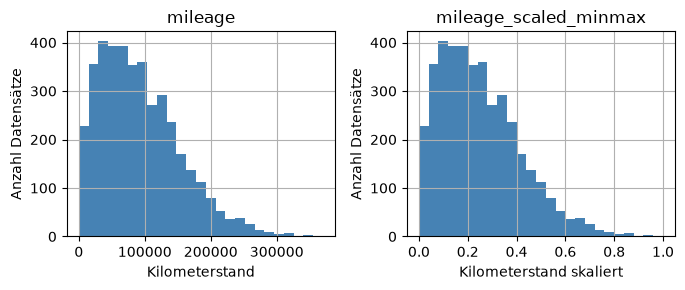

In [36]:
# Min-Max scaling
df_dpspick_autoscout['mileage_scaled_minmax'] = ((df_dpspick_autoscout['mileage'] - df_dpspick_autoscout['mileage'].min()) #Minimum von jedem Wert abziehen
                               / (df_dpspick_autoscout['mileage'].max() - df_dpspick_autoscout['mileage'].min()))   #Durch die Spannweite teilen; Ergebnis zwischen 0 und 1

# Compare original and scaled values
ax = df_dpspick_autoscout[['mileage', 'mileage_scaled_minmax']].hist(
    bins=25,                                                                            #Pro Spalte ein Histogramm mit 25 Intervallen erstellen
    figsize=(7, 3),                                                                     #Gesamtgrösse der Abbildung in Zoll
    color='steelblue')                                                                  #Balkenfarbe festlegen

for axis, label in zip(ax.flatten(), ['Kilometerstand', 'Kilometerstand skaliert']):    #Achsen und Beschriftungen paarweise durchlaufen
                                                                                        #flatten(): Achsenanordnung abflachen; zip(): paarweise verbinden
    axis.set_ylim(bottom=0)                                                             #y-Achse bei 0 beginnen lassen; obere Grenze automatisch bestimmen
    axis.set_xlabel(label)                                                              #Jeweils passende x-Achsenbeschriftung setzen
    axis.set_ylabel('Anzahl Datensätze')                                                #y-Achse beschriften

plt.tight_layout()                                                                      #Abstände zwischen den Diagrammen anpassen
plt.show()                                                                              #Beide Histogramme anzeigen

#ANPASSEN: df überall an deinen Tabellennamen, z. B. df_autoscout oder df_apartments
#ANPASSEN: mileage überall an die vorhandene numerische Ausgangsspalte
#ANPASSEN: mileage_scaled_minmax überall an den gewünschten neuen Spaltennamen
#ANPASSEN: Die beiden Beschriftungen in der zip()-Liste an dein Merkmal
#OPTIONAL: bins, figsize und color ändern
#BEI VORGEGEBENER Y-GRENZE: axis.set_ylim(0, 500) statt axis.set_ylim(bottom=0)

#### Min-Max Scaling (scikit-learn)
- **Zweck:** Numerische Werte mithilfe von `MinMaxScaler()` auf den Bereich **0 bis 1** skalieren, damit unterschiedlich grosse Zahlenwerte vergleichbar werden
- **Funktionsweise:** `MinMaxScaler()` verwendet dieselbe Formel wie die manuelle Min-Max-Skalierung: `(Wert − Minimum) / (Maximum − Minimum)`. Das Minimum wird zu 0, das Maximum zu 1
- **Voraussetzung:** Die zu skalierende Spalte muss numerische Werte enthalten. Für den Vergleich mit `np.allclose()` muss die manuelle Skalierung bereits durchgeführt worden sein
- **Kontrolle:** `np.allclose()` vergleicht die manuell berechneten und die mit scikit-learn skalierten Werte. Das Ergebnis `True` bestätigt, dass beide Verfahren innerhalb kleiner numerischer Toleranzen übereinstimmen

In [38]:
# Min-Max scaling (scikit-learn version)
from sklearn.preprocessing import MinMaxScaler                                  #MinMaxScaler importieren: numerische Werte standardmässig auf 0 bis 1 skalieren

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = MinMaxScaler() #Scaler-Objekt für die Min-Max-Skalierung erstellen
df_dpspick_autoscout['mileage_scaled_minmax_sklearn'] = scaler.fit_transform(   #Skalierte Werte in neuer Spalte speichern
    df_dpspick_autoscout[['mileage']]).ravel()                                  #fit_transform(): Minimum und Maximum bestimmen und Werte auf 0 bis 1 skalieren
                                                                                #[['mileage']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                                #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df_dpspick_autoscout['mileage_scaled_minmax'],                #Manuelle und sklearn-Skalierung miteinander vergleichen
                  df_dpspick_autoscout['mileage_scaled_minmax_sklearn']))       #allclose(): Werte innerhalb kleiner numerischer Toleranzen vergleichen

#ANPASSEN: mileage überall durch die zu skalierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_scaled_minmax_sklearn an den gewünschten neuen Spaltennamen anpassen
#ANPASSEN: mileage_scaled_minmax an den Namen der zuvor manuell skalierten Spalte anpassen
#NICHTS ANPASSEN: MinMaxScaler(), fit_transform(), ravel() und np.allclose() bleiben unverändert
#VORAUSSETZUNG: Die manuelle Skalierung muss bereits durchgeführt worden sein, damit np.allclose() funktioniert

True


### Max-Absolute Scaling (manuell)

Ist ein Skalierungsverfahren, bei dem jeder Wert durch den grössten Absolutwert des Merkmals geteilt wird, sodass alle Werte zwischen −1 und 1 liegen, ohne den Nullpunkt oder die Form der Verteilung zu verändern
- **Zweck:** Numerische Werte durch den grössten Absolutwert der Spalte dividieren, um sie auf den Bereich **−1 bis 1** zu skalieren (bei ausschliesslich positiven Werten: 0 bis 1)
- **Formel:** `Wert / max(abs(alle Werte))` – der betragsmässig grösste Wert wird zu −1 oder 1; der Wert 0 bleibt unverändert
- **Unterschied zu Min-Max:** Bei Max-Absolute wird kein Minimum abgezogen. Deshalb bleibt der Nullpunkt erhalten, während bei Min-Max der kleinste Wert zu 0 wird
- **Erkenntnis:** Die Skalierung verändert die Grössenordnung, aber nicht die Verteilungsform oder die relativen Abstände. Die Histogramme zeigen dieselbe Verteilung, jedoch mit unterschiedlichen x-Achsenwerten

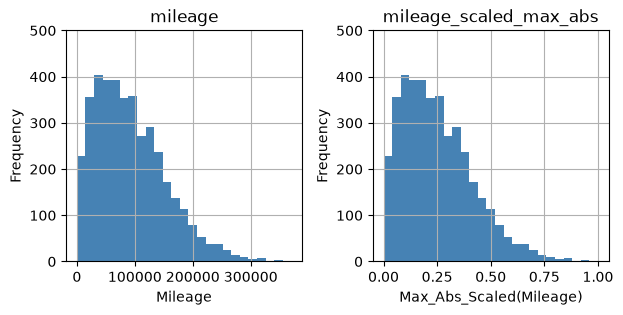

In [39]:
# Max-Absolute scaling of the variable 'mileage' (by hand)
df_dpspick_autoscout['mileage_scaled_max_abs'] = df_dpspick_autoscout['mileage'] / df_dpspick_autoscout['mileage'].abs().max() #Jeden Kilometerstand durch den grössten Absolutwert dividieren
                                                                                    #abs(): Absolutwerte bilden; max(): grössten Absolutwert bestimmen
                                                                                    #Ergebnis: Werte zwischen -1 und 1 (bei positiven Kilometerständen 0 bis 1)

# Histogram of the variable 'mileage' and 'mileage_scaled_max_abs'
ax = df_dpspick_autoscout[['mileage', 'mileage_scaled_max_abs']].hist(bins=25,   #Originale und skalierte Kilometerstände als zwei Histogramme darstellen
                                                             figsize=(7, 3),    #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                                             color='steelblue') #bins=25: 25 Intervalle; color: Balkenfarbe
                                                                                #hist(): Häufigkeitsverteilung darstellen; ax speichert die Diagrammachsen

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Max_Abs_Scaled(Mileage)']):   #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                                #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(0, 500)                                                       #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #set_xlabel(): x-Achse beschriften
    axis.set_ylabel('Frequency')                                                #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                                      #Beide Histogramme anzeigen

#ANPASSEN: mileage überall durch die zu skalierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_scaled_max_abs an den gewünschten neuen Spaltennamen anpassen
#ANPASSEN: ['Mileage', 'Max_Abs_Scaled(Mileage)'] an die gewünschten x-Achsenbeschriftungen anpassen
#ANPASSEN: bins=25, figsize=(7, 3), color='steelblue' und set_ylim(0, 500) bei Bedarf anpassen
#NICHTS ANPASSEN: abs(), max(), hist(), flatten(), zip(), set_xlabel(), set_ylabel() und plt.show() bleiben unverändert

#### Max-Absolute Scaling (scikit-learn)

- **Zweck:** Numerische Werte mit `MaxAbsScaler()` automatisch durch den grössten Absolutwert skalieren (Bereich −1 bis 1)
- **Funktionsweise:** `fit_transform()` bestimmt den grössten Absolutwert der Spalte und dividiert sämtliche Werte dadurch. Im Gegensatz zu Min-Max wird kein Minimum abgezogen, weshalb 0 unverändert bleibt
- **Voraussetzung:** Die Ausgangsspalte muss numerisch sein. Für den Vergleich mit `np.allclose()` muss die manuelle Max-Absolute-Skalierung bereits durchgeführt worden sein
- **Kontrolle:** `np.allclose()` überprüft, ob die manuelle Berechnung und `MaxAbsScaler()` innerhalb kleiner numerischer Toleranzen übereinstimmen. Das Ergebnis `True` bestätigt, dass beide Verfahren praktisch identische Werte liefern

In [40]:
# Max-Absolute scaling of the variable 'mileage' (scikit-learn version)
from sklearn.preprocessing import MaxAbsScaler                                  #MaxAbsScaler importieren: Werte durch den grössten Absolutwert skalieren

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = MaxAbsScaler() #Scaler-Objekt für die Max-Absolute-Skalierung erstellen
df_dpspick_autoscout['mileage_scaled_max_abs_sklearn'] = scaler.fit_transform(  #Skalierte Kilometerstände in neuer Spalte speichern
    df_dpspick_autoscout[['mileage']]).ravel()                                  #fit_transform(): Grössten Absolutwert bestimmen und Werte dadurch dividieren
                                                                                #[['mileage']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                                #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df_dpspick_autoscout['mileage_scaled_max_abs'],               #Manuelle und sklearn-Skalierung miteinander vergleichen
                  df_dpspick_autoscout['mileage_scaled_max_abs_sklearn']))      #allclose(): Werte innerhalb kleiner numerischer Toleranzen vergleichen
                                                                                #True: Beide Verfahren liefern praktisch identische Werte

#ANPASSEN: mileage überall durch die zu skalierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_scaled_max_abs_sklearn an den gewünschten neuen Spaltennamen anpassen
#ANPASSEN: mileage_scaled_max_abs an den Namen der zuvor manuell skalierten Spalte anpassen
#NICHTS ANPASSEN: MaxAbsScaler(), fit_transform(), ravel() und np.allclose() bleiben unverändert
#VORAUSSETZUNG: Die manuell skalierte Spalte muss bereits existieren, damit np.allclose() funktioniert

True


### Robust Scaling

**Zweck:** Numerische Werte mithilfe des Medians und des Interquartilsabstands (IQR) skalieren. Besonders geeignet für Daten mit **Ausreissern**, da Median und IQR weniger empfindlich gegenüber extremen Werten sind
- **Formel:** `(Wert − Median) / (Q3 − Q1)` – vom ursprünglichen Wert den Median abziehen und durch den Interquartilsabstand teilen
- **Methoden:** `median()` bestimmt den mittleren Wert (50. Perzentil); `quantile(0.25)` bestimmt das untere Quartil (Q1) und `quantile(0.75)` das obere Quartil (Q3). Die Differenz `Q3 − Q1` ergibt den IQR und beschreibt die Streuung der mittleren 50 % der Daten
- **Erkenntnis:** Der Median wird zu 0; Werte darunter werden negativ, Werte darüber positiv. Es gibt keinen festen Wertebereich wie bei Min-Max Scaling. Die Verteilungsform bleibt erhalten, die x-Achse wird verschoben und skaliert
- **Unterschied zu Min-Max und Max-Absolute:** Robust Scaling verwendet Median und IQR statt Minimum oder Maximum. Dadurch beeinflussen Ausreisser die Skalierung weniger stark, bleiben aber weiterhin im Datensatz enthalten

#### Robus Scaling (manuell)

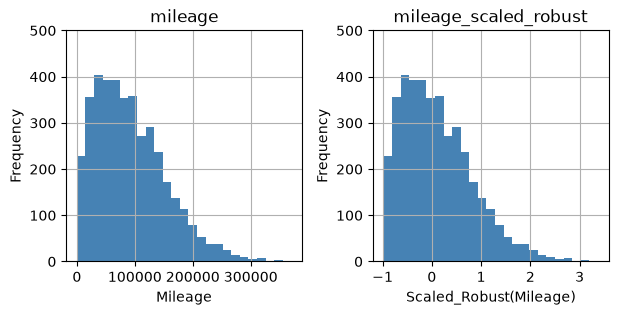

In [41]:
# Robust scaling of the variable 'mileage' (by hand)
df_dpspick_autoscout['mileage_scaled_robust'] = (df_dpspick_autoscout['mileage'] - df_dpspick_autoscout['mileage'].median()) / \
    (df_dpspick_autoscout['mileage'].quantile(0.75)                             #quantile(0.75): 75. Perzentil (Q3) bestimmen
     - df_dpspick_autoscout['mileage'].quantile(0.25))                          #quantile(0.25): 25. Perzentil (Q1) bestimmen
                                                                                #median(): mittleren Wert bestimmen (50. Perzentil)
                                                                                #Formel: (Wert - Median) / (Q3 - Q1); Q3 - Q1 = IQR
                                                                                #Ergebnis: Median wird 0; Ausreisser beeinflussen die Skalierung weniger

# Histogram of the variable 'mileage' and 'mileage_scaled_robust'
ax = df_dpspick_autoscout[['mileage', 'mileage_scaled_robust']].hist(bins=25,   #Originale und skalierte Werte als zwei Histogramme darstellen
                                                            figsize=(7, 3),     #figsize: Abbildungsgrösse (Breite × Höhe in Zoll)
                                                            color='steelblue')  #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle
                                                                                #color: Balkenfarbe; ax speichert die Diagrammachsen

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Scaled_Robust(Mileage)']):    #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                                #flatten(): Achsenanordnung in 1D umwandeln
                                                                                #zip(): Achsen und Beschriftungen paarweise verbinden
    axis.set_ylim(0, 500)                                                       #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #set_xlabel(): x-Achse beschriften
    axis.set_ylabel('Frequency')                                                #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                                      #Beide Histogramme anzeigen

#ANPASSEN: mileage überall durch die zu skalierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_scaled_robust an den gewünschten Namen der neuen Spalte anpassen
#ANPASSEN: ['Mileage', 'Scaled_Robust(Mileage)'] an die jeweiligen Achsenbeschriftungen anpassen
#ANPASSEN: bins=25, figsize=(7, 3), color='steelblue' und set_ylim(0, 500) bei Bedarf anpassen
#NICHTS ANPASSEN: median(), quantile(0.75), quantile(0.25), hist(), flatten(), zip() und plt.show()
#VORAUSSETZUNG: Numerische Spalte mit IQR > 0; pandas und matplotlib.pyplot als plt müssen importiert sein

#### Robust Scaling (scikit-learn)

- **Zweck:** Numerische Werte mit `RobustScaler()` automatisch anhand des Medians und des Interquartilsabstands (IQR) skalieren, um den Einfluss von Ausreissern zu reduzieren.
- **Funktionsweise:** `fit_transform()` bestimmt den Median und den IQR (`Q3 − Q1`) und skaliert die Werte mit der Formel `(Wert − Median) / IQR`.
- **Erkenntnis:** Der Median wird zu 0. Werte darunter werden negativ, Werte darüber positiv. Anders als bei Min-Max Scaling gibt es keinen festen Wertebereich.
- **Kontrolle:** `np.allclose()` vergleicht die manuelle Berechnung mit der scikit-learn-Version. `True` bestätigt, dass beide Verfahren innerhalb kleiner numerischer Toleranzen übereinstimmen.
- **Voraussetzung:** Für den Vergleich muss die manuell skalierte Spalte bereits existieren.

In [42]:
# Robust scaling of the variable 'mileage' (scikit-learn version)
from sklearn.preprocessing import RobustScaler                                  #RobustScaler importieren: Werte anhand von Median und IQR skalieren

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = RobustScaler() #Scaler-Objekt für die robuste Skalierung erstellen
df_dpspick_autoscout['mileage_scaled_robust_sklearn'] = scaler.fit_transform(           #Robust skalierte Kilometerstände in neuer Spalte speichern
    df_dpspick_autoscout[['mileage']]).ravel()                                          #fit_transform(): Median und IQR bestimmen und Werte damit skalieren
                                                                                #[['mileage']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                                #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df_dpspick_autoscout['mileage_scaled_robust'],                #Manuelle und sklearn-Skalierung miteinander vergleichen
                  df_dpspick_autoscout['mileage_scaled_robust_sklearn']))       #allclose(): Werte innerhalb kleiner numerischer Toleranzen vergleichen
                                                                                #True: Beide Verfahren liefern praktisch identische Ergebnisse

#ANPASSEN: mileage überall durch die zu skalierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_scaled_robust_sklearn an den gewünschten Namen der neuen Spalte anpassen
#ANPASSEN: mileage_scaled_robust an den Namen der zuvor manuell skalierten Spalte anpassen
#NICHTS ANPASSEN: RobustScaler(), fit_transform(), ravel() und np.allclose() bleiben unverändert
#VORAUSSETZUNG: Die manuelle Robust-Skalierung muss bereits ausgeführt worden sein, damit np.allclose() funktioniert

True


### Data Standardization (Z-Score Normalization)

- **Definition:** Standardisierung ist ein Skalierungsverfahren, bei dem numerische Werte so umgerechnet werden, dass sie einen **Mittelwert von 0 und eine Standardabweichung von 1** aufweisen.
- **Zweck:** Numerische Merkmale mit unterschiedlichen Grössenordnungen vergleichbar machen, damit grosse Zahlenwerte ein Modell nicht allein aufgrund ihrer Skala stärker beeinflussen. Durch die Standardisierung wird zudem erkennbar, wie viele Standardabweichungen ein Wert über oder unter dem Mittelwert liegt.
- **Formel:** `(Wert − Mittelwert) / Standardabweichung` – von jedem Wert wird der Mittelwert abgezogen und das Ergebnis durch die Standardabweichung geteilt.
- **Mittelwert (μ):** Durchschnitt aller Werte eines Merkmals; wird durch die Standardisierung auf 0 verschoben.
- **Standardabweichung (σ):** Mass für die Streuung der Werte um den Mittelwert; wird durch die Standardisierung auf 1 gebracht.
- **Erkenntnis:** Werte über dem Mittelwert werden positiv, Werte darunter negativ. Die Verteilungsform bleibt unverändert und die Daten werden **nicht automatisch normalverteilt**. Im Gegensatz zu Min-Max Scaling gibt es keinen festen Wertebereich. In scikit-learn wird dafür `StandardScaler()` verwendet.

#### Data Standardization / Z-Score Normalization (manuell)

- **Definition:** Standardisierung ist ein Skalierungsverfahren, bei dem numerische Werte so umgerechnet werden, dass sie einen Mittelwert von 0 und eine Standardabweichung von 1 aufweisen.
- **Zweck:** Merkmale unterschiedlicher Grössenordnungen vergleichbar machen, damit grosse Zahlenwerte ein Modell nicht allein aufgrund ihrer Skala stärker beeinflussen. Ein Z-Score zeigt zudem, wie viele Standardabweichungen ein Wert vom Mittelwert entfernt liegt.
- **Formel:** `(Wert − Mittelwert) / Standardabweichung` – von jedem Wert den Mittelwert abziehen und durch die Standardabweichung dividieren.
- **Methoden:** `mean()` berechnet den arithmetischen Mittelwert; `std()` bestimmt die Standardabweichung und damit die Streuung der Werte um den Mittelwert.
- **Erkenntnis:** Der Mittelwert wird zu 0 und die Standardabweichung zu 1. Werte über dem Mittelwert werden positiv, darunter negativ. Es gibt keinen festen Wertebereich. Die Verteilungsform bleibt unverändert und die Daten werden nicht automatisch normalverteilt.

In [ ]:
# Z-score Normalization of the variable 'mileage' (by hand)
df_autoscout['mileage_scaled_z'] = ((df_autoscout['mileage'] - df_autoscout['mileage'].mean())  #Von jedem Kilometerstand den Mittelwert abziehen
                                   / df_autoscout['mileage'].std())                             #Durch die Standardabweichung dividieren
                                                                                                #mean(): arithmetischen Mittelwert berechnen
                                                                                                #std(): Standardabweichung bestimmen (standardmässig Stichprobe, ddof=1)
                                                                                                #Ergebnis: Mittelwert ≈ 0 und Standardabweichung ≈ 1
                                                                                                #Positive Werte liegen über, negative unter dem Mittelwert

# Histogram of the variable 'mileage' and 'mileage_scaled_z'
ax = df_autoscout[['mileage', 'mileage_scaled_z']].hist(bins=25,                #Originale und standardisierte Kilometerstände als zwei Histogramme darstellen
                                                        figsize=(7, 3),         #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                                        color='steelblue')      #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle
                                                                                #color: Balkenfarbe; ax speichert die Diagrammachsen
                                                                                #Erkenntnis: Verteilungsform bleibt gleich, x-Achse wird verschoben und skaliert

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Scaled_Z(Mileage)']):         #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                                #flatten(): Achsenanordnung in 1D umwandeln
                                                                                #zip(): Achsen und Beschriftungen paarweise verbinden
    axis.set_ylim(0, 500)                                                       #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #set_xlabel(): x-Achse beschriften
    axis.set_ylabel('Frequency')                                                #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                                      #Beide Histogramme anzeigen

#ANPASSEN: df_autoscout überall durch den verwendeten DataFrame ersetzen (z. B. df_apartments)
#ANPASSEN: mileage überall durch die zu standardisierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_scaled_z überall an den gewünschten Namen der neuen Spalte anpassen
#ANPASSEN: ['Mileage', 'Scaled_Z(Mileage)'] an die jeweiligen Achsenbeschriftungen anpassen
#ANPASSEN: bins=25, figsize=(7, 3), color='steelblue' und set_ylim(0, 500) bei Bedarf anpassen
#NICHTS ANPASSEN: mean(), std(), hist(), flatten(), zip(), set_xlabel(), set_ylabel() und plt.show()
#VORAUSSETZUNG: Numerische Spalte mit mindestens zwei gültigen, unterschiedlichen Werten; pandas und matplotlib.pyplot als plt importiert

### Data Standardization / Z-Score Normalization (scikit-learn)

- **Zweck:** Numerische Werte mit `StandardScaler()` automatisch standardisieren, sodass sie einen Mittelwert von 0 und eine Standardabweichung von 1 aufweisen.
- **Funktionsweise:** `fit_transform()` bestimmt den Mittelwert und die Standardabweichung und berechnet für jeden Wert den Z-Score: `(Wert − Mittelwert) / Standardabweichung`.
- **Wichtiger Unterschied:** `pandas.std()` verwendet standardmässig `ddof=1` (Division durch `n−1` bei der Varianzberechnung), während `StandardScaler()` `ddof=0` verwendet (Division durch `n`). Deshalb unterscheiden sich die Ergebnisse leicht.
- **Kontrolle:** `np.allclose()` prüft, ob zwei Berechnungen innerhalb kleiner numerischer Toleranzen übereinstimmen. Der erste Vergleich liefert normalerweise `False`, da unterschiedliche Standardabweichungen verwendet werden. Mit `std(ddof=0)` liefert der zweite Vergleich `True`.
- **Erkenntnis:** `ddof=0` sorgt dafür, dass die manuelle Berechnung dieselbe Standardabweichung wie scikit-learn verwendet. Die Ergebnisse stimmen dadurch praktisch überein.

In [ ]:
# Z-score Normalization of the variable 'mileage' (scikit-learn version)
from sklearn.preprocessing import StandardScaler                    #StandardScaler importieren: Werte auf Mittelwert 0 und Standardabweichung 1 standardisieren

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = StandardScaler() #Scaler-Objekt für die Z-Score-Standardisierung erstellen
df_autoscout['mileage_scaled_z_sklearn'] = scaler.fit_transform(    #Standardisierte Kilometerstände in neuer Spalte speichern
    df_autoscout[['mileage']]).ravel()                              #fit_transform(): Mittelwert und Standardabweichung bestimmen und Werte standardisieren
                                                                    #[['mileage']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                    #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Note: pandas .std() divides by n-1, StandardScaler divides by n,
# so the results differ slightly
print(np.allclose(df_autoscout['mileage_scaled_z'],                 #Manuelle und sklearn-Standardisierung vergleichen
                  df_autoscout['mileage_scaled_z_sklearn']))        #allclose(): Werte innerhalb kleiner numerischer Toleranzen vergleichen
                                                                    #Erwartet False: pandas.std() verwendet ddof=1, StandardScaler ddof=0
                                                                    #Erkenntnis: Unterschiedliche Standardabweichungen führen zu leicht anderen Ergebnissen

# Check against the by-hand formula with the standard deviation
# divided by n (ddof=0)
z_ddof0 = (df_autoscout['mileage'] - df_autoscout['mileage'].mean()) / df_autoscout['mileage'].std(ddof=0) #Z-Score manuell mit derselben Standardabweichung wie sklearn berechnen
                                                                                                           #mean(): arithmetischen Mittelwert berechnen
                                                                                                           #std(ddof=0): Standardabweichung mit Division durch n statt n-1 berechnen
                                                                                                           #ddof: Freiheitsgradkorrektur; pandas verwendet standardmässig ddof=1

print(np.allclose(z_ddof0, df_autoscout['mileage_scaled_z_sklearn']))       #Manuelle Berechnung mit ddof=0 und sklearn vergleichen
                                                                            #Erwartet True: Beide verwenden dieselbe Berechnung

#ANPASSEN: df_autoscout überall durch den verwendeten DataFrame ersetzen (z. B. df_apartments)
#ANPASSEN: mileage überall durch die zu standardisierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_scaled_z_sklearn an den gewünschten Namen der neuen Spalte anpassen
#ANPASSEN: mileage_scaled_z an den Namen der zuvor manuell standardisierten Spalte anpassen
#NICHTS ANPASSEN: StandardScaler(), fit_transform(), ravel(), mean(), std(ddof=0) und np.allclose()
#VORAUSSETZUNG: Die manuell standardisierte Spalte muss bereits existieren, damit der erste Vergleich funktioniert

# Transformation
In statistics, Data Transformation involves applying mathematical functions to data to meet the assumptions of statistical models, improve interpretability, or enhance the robustness of analysis

### Data Transformation: Logarithmic Transformation

- **Definition:** Die Logarithmus-Transformation ist ein Verfahren, bei dem numerische Werte mithilfe einer Logarithmusfunktion umgerechnet werden, um ihre Verteilung zu verändern.
- **Zweck:** Stark rechtsschiefe Verteilungen reduzieren, grosse Werte komprimieren und nichtlineare Zusammenhänge abschwächen, damit statistische Modelle die Daten besser verarbeiten können.
- **Formel:** `Y' = log(Y)` – jeder ursprüngliche Wert wird durch seinen natürlichen Logarithmus (Basis e) ersetzt.
- **Methode:** `np.log()` berechnet den natürlichen Logarithmus für jeden Wert einer numerischen Spalte. Die Ergebnisse werden in einer neuen Spalte gespeichert.
- **Voraussetzung:** Die Ausgangswerte müssen grösser als 0 sein. Bei `np.log(0)` entsteht `-inf` (negativ unendlich), bei negativen Werten `NaN`.
- **Erkenntnis:** Grosse Werte werden stärker komprimiert als kleine, wodurch eine rechtsschiefe Verteilung symmetrischer werden kann. Im Gegensatz zum Scaling verändert die Logarithmus-Transformation die Form der Verteilung. Eine Normalverteilung wird nicht garantiert.
- **Auswirkung auf Modelle:** Ein exponentieller Zusammenhang kann durch Logarithmieren der Zielvariable annähernd linear werden. Dadurch können systematische Muster in den Residuen (Abweichungen zwischen beobachteten und vorhergesagten Werten) reduziert werden.

In [ ]:
# Log-Transformation of the variable 'mileage'
df_autoscout['mileage_log'] = np.log(df_autoscout['mileage'])       #Kilometerstände logarithmieren und in neuer Spalte speichern
                                                                    #np.log(): natürlichen Logarithmus (Basis e) für jeden Wert berechnen
                                                                    #Voraussetzung: Werte > 0; bei 0 entsteht -inf, bei negativen Werten NaN

# Histogram of the variable 'mileage' and 'mileage_log'
ax = df_autoscout[['mileage', 'mileage_log']].hist(bins=25,                 #Originale und logarithmierte Kilometerstände als zwei Histogramme darstellen
                                                  figsize=(7, 3),           #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                                  color='steelblue')        #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle
                                                                            #color: Balkenfarbe; ax speichert die Diagrammachsen
                                                                            #Erkenntnis: Logarithmierung kann Rechtsschiefe reduzieren und Verteilungsform verändern

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Log(Mileage)']):          #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                            #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(bottom=0)                                                 #set_ylim(): y-Achse bei 0 beginnen lassen; Maximum automatisch bestimmen
    axis.set_xlabel(label)                                                  #set_xlabel(): x-Achse mit der jeweiligen Beschriftung versehen
    axis.set_ylabel('Frequency')                                            #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                                  #Beide Histogramme anzeigen

#ANPASSEN: df_autoscout überall durch den verwendeten DataFrame ersetzen (z. B. df_apartments)
#ANPASSEN: mileage überall durch die zu transformierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_log überall an den gewünschten Namen der neuen Spalte anpassen
#ANPASSEN: ['Mileage', 'Log(Mileage)'] an die jeweiligen Achsenbeschriftungen anpassen
#OPTIONAL: bins=25, figsize=(7, 3) und color='steelblue' bei Bedarf ändern
#BEI VORGEGEBENER Y-GRENZE: axis.set_ylim(0, 1200) statt axis.set_ylim(bottom=0)
#NICHTS ANPASSEN: np.log(), hist(), flatten(), zip(), set_xlabel(), set_ylabel() und plt.show()
#VORAUSSETZUNG: Numerische Spalte mit ausschliesslich positiven Werten; numpy als np und matplotlib.pyplot als plt importiert

### Data Transformation: Square Root Transformation (SQRT)

- **Definition:** Die Quadratwurzel-Transformation (SQRT) ist ein Verfahren, bei dem numerische Werte durch ihre Quadratwurzel ersetzt werden, um die Verteilung der Daten zu verändern.
- **Zweck:** Grosse Werte komprimieren, rechtsschiefe Verteilungen reduzieren und den Einfluss hoher Werte bzw. Ausreisser abschwächen.
- **Formel:** `Y' = √Y` – jeder ursprüngliche Wert wird durch seine Quadratwurzel ersetzt (z. B. √100 = 10).
- **Methode:** `np.sqrt()` berechnet die Quadratwurzel jedes Werts einer numerischen Spalte. Die Ergebnisse werden in einer neuen Spalte gespeichert.
- **Voraussetzung:** Die Ausgangswerte müssen ≥ 0 sein. Nullwerte sind erlaubt (`√0 = 0`); negative Werte ergeben `NaN`.
- **Erkenntnis:** Grosse Werte werden stärker komprimiert als kleine, wodurch eine rechtsschiefe Verteilung symmetrischer werden kann. Die Verteilungsform kann sich verändern, eine Normalverteilung wird jedoch nicht garantiert.
- **Unterschied zur Logarithmus-Transformation:** SQRT ist bei grossen Werten weniger stark komprimierend als `np.log()` und kann im Gegensatz dazu auch Nullwerte verarbeiten.

In [ ]:
# SQRT-Transformation of the variable 'mileage'
df_autoscout['mileage_sqrt'] = np.sqrt(df_autoscout['mileage'])     #Quadratwurzel jedes Kilometerstands berechnen und in neuer Spalte speichern
                                                                    #np.sqrt(): Quadratwurzel jedes Werts berechnen (z. B. √100 = 10)
                                                                    #Voraussetzung: Werte >= 0; negative Werte ergeben NaN
                                                                    #Erkenntnis: Grosse Werte werden komprimiert; Rechtsschiefe kann abnehmen

# Histogram of the variable 'mileage' and 'mileage_sqrt'
ax = df_autoscout[['mileage', 'mileage_sqrt']].hist(bins=25,            #Originale und wurzeltransformierte Kilometerstände als zwei Histogramme darstellen
                                                   figsize=(7, 3),      #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                                   color='steelblue')   #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle
                                                                        #color: Balkenfarbe; ax speichert die Diagrammachsen
                                                                        #Erkenntnis: SQRT kann die Verteilungsform verändern und Rechtsschiefe reduzieren

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'SQRT(Mileage)']):     #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                        #flatten(): Achsenanordnung in 1D umwandeln
                                                                        #zip(): Achsen und Beschriftungen paarweise verbinden
    axis.set_ylim(bottom=0)                                             #set_ylim(): y-Achse bei 0 beginnen lassen; obere Grenze automatisch bestimmen
    axis.set_xlabel(label)                                              #set_xlabel(): x-Achse mit der jeweiligen Beschriftung versehen
    axis.set_ylabel('Frequency')                                        #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                              #Beide Histogramme anzeigen

#ANPASSEN: df_autoscout überall durch den verwendeten DataFrame ersetzen (z. B. df_apartments)
#ANPASSEN: mileage überall durch die zu transformierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_sqrt überall an den gewünschten Namen der neuen Spalte anpassen
#ANPASSEN: ['Mileage', 'SQRT(Mileage)'] an die jeweiligen Achsenbeschriftungen anpassen
#OPTIONAL: bins=25, figsize=(7, 3) und color='steelblue' bei Bedarf ändern
#BEI VORGEGEBENER Y-GRENZE: axis.set_ylim(0, 500) statt axis.set_ylim(bottom=0)
#NICHTS ANPASSEN: np.sqrt(), hist(), flatten(), zip(), set_xlabel(), set_ylabel() und plt.show()
#VORAUSSETZUNG: Numerische Spalte mit nichtnegativen Werten; numpy als np und matplotlib.pyplot als plt importiert

### Data Transformation: Box-Cox Transformation

- **Definition:** Die Box-Cox-Transformation ist ein Verfahren zur Umrechnung numerischer Werte, bei dem die geeignete Transformation anhand eines Parameters Lambda (λ) automatisch bestimmt wird.
- **Zweck:** Schiefe Verteilungen reduzieren, grosse Werte transformieren und die Daten einer Normalverteilung annähern.
- **Formel:** `Y' = (Y^λ − 1) / λ` für `λ ≠ 0`; bei `λ = 0` gilt `Y' = log(Y)`.
- **Methode:** `boxcox()` aus `scipy.stats` schätzt automatisch den optimalen Parameter λ und transformiert die Werte. Ziel der Schätzung ist eine möglichst gute Annäherung an eine Normalverteilung.
- **Parameter λ (Lambda):**
  - `λ = 0`: Logarithmus-Transformation (`log(Y)`).
  - `λ = 0.5`: Mit der Quadratwurzel-Transformation verwandt (`2 × (√Y − 1)`).
  - `λ = 1`: Entspricht `Y − 1` (Verschiebung ohne Veränderung der Verteilungsform).
- **Rückgabewerte:** `boxcox()` liefert die transformierten Werte und das geschätzte Lambda. Mit `_` kann Lambda ignoriert werden.
- **Voraussetzung:** Alle Ausgangswerte müssen strikt positiv sein (`Y > 0`). Nullwerte und negative Werte sind nicht erlaubt.
- **Erkenntnis:** Im Gegensatz zu `np.log()` und `np.sqrt()` wird die Transformation anhand der Daten automatisch angepasst. Dadurch kann Box-Cox eine schiefe Verteilung besser an eine Normalverteilung annähern; eine Normalverteilung wird jedoch nicht garantiert.

In [ ]:
# Import the boxcox function from scipy
from scipy.stats import boxcox                                          #boxcox() importieren: Box-Cox-Transformation zur Annäherung an eine Normalverteilung

# Box-Cox Transformation of the variable 'mileage'
df_autoscout['mileage_boxcox'], _ = boxcox(df_autoscout['mileage'])     #Kilometerstände transformieren und in neuer Spalte speichern
                                                                        #boxcox(): Lambda (λ) automatisch schätzen und Werte transformieren
                                                                        #Rückgabe: transformierte Werte und geschätztes Lambda
                                                                        #_: Lambda ignorieren, da nur die transformierten Werte benötigt werden
                                                                        #Voraussetzung: Alle Werte > 0; keine Nullwerte oder negativen Werte
                                                                        #Erkenntnis: λ=0 entspricht log(x); λ=0.5 ist mit √x verwandt; λ=1 entspricht x−1

# Histogram of the variable 'mileage' and 'mileage_boxcox'
ax = df_autoscout[['mileage', 'mileage_boxcox']].hist(bins=25,          #Originale und Box-Cox-transformierte Kilometerstände als zwei Histogramme darstellen
                                                     figsize=(7, 3),    #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                                     color='steelblue') #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle
                                                                        #color: Balkenfarbe; ax speichert die Diagrammachsen
                                                                        #Erkenntnis: Box-Cox kann Schiefe reduzieren und Verteilungen symmetrischer machen
                                                                        #Eine Normalverteilung wird nicht garantiert

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Box-Cox(Mileage)']):  #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                        #flatten(): Achsenanordnung in 1D umwandeln
                                                                        #zip(): Achsen und Beschriftungen paarweise verbinden
    axis.set_ylim(bottom=0)                                             #set_ylim(): y-Achse bei 0 beginnen lassen; obere Grenze automatisch bestimmen
    axis.set_xlabel(label)                                              #set_xlabel(): x-Achse mit der jeweiligen Beschriftung versehen
    axis.set_ylabel('Frequency')                                        #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                              #Beide Histogramme anzeigen

#ANPASSEN: df_autoscout überall durch den verwendeten DataFrame ersetzen (z. B. df_apartments)
#ANPASSEN: mileage überall durch die zu transformierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_boxcox überall an den gewünschten Namen der neuen Spalte anpassen
#ANPASSEN: ['Mileage', 'Box-Cox(Mileage)'] an die jeweiligen Achsenbeschriftungen anpassen
#OPTIONAL: bins=25, figsize=(7, 3) und color='steelblue' bei Bedarf ändern
#BEI VORGEGEBENER Y-GRENZE: axis.set_ylim(0, 500) statt axis.set_ylim(bottom=0)
#NICHTS ANPASSEN: boxcox(), hist(), flatten(), zip(), set_xlabel(), set_ylabel() und plt.show()
#VORAUSSETZUNG: Numerische Spalte mit ausschliesslich positiven Werten; scipy und matplotlib.pyplot als plt verfügbar

## Combining & Organizing Data

### Reading Geocoded Data (CSV)

- **Definition:** Geocodierte Daten sind Datensätze mit geografischen Informationen, insbesondere Breitengrad (`lat`) und Längengrad (`lon`), die eine räumliche Zuordnung ermöglichen.
- **Zweck:** Geografische Informationen aus einer CSV-Datei einlesen, um sie anschliessend mit anderen Datensätzen kombinieren oder räumlich auswerten zu können.
- **Methode:** `pd.read_csv()` liest eine CSV-Datei ein und erstellt daraus einen pandas-DataFrame.
- **Wichtige Parameter:**
  - `sep=';'`: Semikolon als Spaltentrennzeichen verwenden.
  - `encoding='utf-8'`: Zeichenkodierung festlegen, damit Umlaute und Sonderzeichen korrekt eingelesen werden.
  - `./`: Aktuelles Arbeitsverzeichnis; kein zusätzlicher Unterordner erforderlich.
- **Wichtige Variablen:**
  - `offer_id`: Eindeutige Kennnummer eines Fahrzeugangebots.
  - `lat`: Geografischer Breitengrad (Nord-Süd-Position).
  - `lon`: Geografischer Längengrad (Ost-West-Position).
  - `bfs_number`: Offizielle Gemeindenummer des Bundesamts für Statistik.
  - `bfs_name`: Offizieller Gemeindename.
- **Erkenntnis:** Geocodierte Daten ermöglichen die geografische Zuordnung von Datensätzen. Über gemeinsame Identifikatoren (z. B. `offer_id`) können sie später mit anderen Daten kombiniert werden.

In [ ]:
# Meaning of variables
# offer_id: unique identifier of the offer on autoscout24.ch
# lat: geographical latitude
# lon: geographical longitude
# bfs_number: official municipality id
# bfs_name: official municipality name
#offer_id: eindeutige Kennnummer eines Fahrzeugangebots (möglicher Schlüssel zum Kombinieren von Daten)
#lat: geografischer Breitengrad (Nord-Süd-Position)
#lon: geografischer Längengrad (Ost-West-Position)
#bfs_number: offizielle Gemeindenummer des Bundesamts für Statistik (BFS)
#bfs_name: offizieller Gemeindename gemäss BFS

# Geocoded data (i.e. data with latitude and longitude)
df_geo = pd.read_csv('./autoscout24_data_geocoded.csv', #Geocodierte Fahrzeugdaten aus der CSV-Datei in einen neuen DataFrame einlesen
                     sep=';',                           #sep: Semikolon als Spaltentrennzeichen verwenden
                     encoding='utf-8')                  #encoding: UTF-8-Zeichenkodierung für Umlaute und Sonderzeichen verwenden
                                                        #pd.read_csv(): CSV-Datei einlesen und als pandas-DataFrame zurückgeben
                                                        #./: Datei liegt im aktuellen Arbeitsverzeichnis (kein Unterordner)

# Show data
df_geo.head() #head(): Standardmässig die ersten 5 Zeilen zur Kontrolle anzeigen

#ANPASSEN: './autoscout24_data_geocoded.csv' durch den tatsächlichen Dateinamen bzw. Dateipfad ersetzen
#ANPASSEN: sep=';' an das verwendete Trennzeichen anpassen (z. B. sep=',')
#ANPASSEN: encoding='utf-8' nur ändern, falls die Datei eine andere Zeichenkodierung verwendet
#OPTIONAL: df_geo durch einen anderen DataFrame-Namen ersetzen
#NICHTS ANPASSEN: pd.read_csv() und .head()
#VORAUSSETZUNG: import pandas as pd; CSV-Datei muss im angegebenen Verzeichnis existieren

### Combining Data: pd.merge()

- **Definition:** `pd.merge()` kombiniert zwei DataFrames anhand einer gemeinsamen Schlüsselspalte (Key), indem Datensätze mit übereinstimmenden Schlüsselwerten zusammengeführt werden
- **Zweck:** Informationen aus verschiedenen Datenquellen verbinden, bspw. Fahrzeugdaten mit geografischen Informationen (Breitengrad, Längengrad und Gemeinde)
- **Methode:** `df1.merge(df2, on='schlüsselspalte')` verbindet zwei DataFrames über die angegebene Schlüsselspalte.
- **Wichtige Parameter:**
  - `on='offer_id'`: Gemeinsame Schlüsselspalte, über welche die Datensätze verbunden werden. Sie muss in beiden DataFrames existieren
  - `how='inner'`: Nur Datensätze übernehmen, deren Schlüssel in beiden DataFrames vorkommt (Standard)
  - `how='left'`: Alle Zeilen des linken DataFrames behalten; fehlende Werte aus dem rechten DataFrame werden mit `NaN` ergänzt
  - `how='right'`: Alle Zeilen des rechten DataFrames behalten; fehlende Werte aus dem linken DataFrame werden mit `NaN` ergänzt
  - `how='outer'`: Alle Schlüsselwerte aus beiden DataFrames übernehmen; fehlende Informationen werden mit `NaN` ergänzt
- **Spaltenauswahl:** `df_geo[['offer_id', 'lat', 'lon', 'bfs_number', 'bfs_name']]` wählt gezielt die Spalten aus, die beim Zusammenführen übernommen werden sollen
- **Ergebnis:** Ein neuer DataFrame (`df2`), der die ursprünglichen Fahrzeugdaten und zusätzlich die geografischen Informationen enthält
- **Wichtig:** Fehlende Übereinstimmungen werden bei einem Inner Join ausgeschlossen. Doppelte Schlüsselwerte können dazu führen, dass sich die Anzahl der Zeilen erhöht
- **Erkenntnis:** `pd.merge()` entspricht dem JOIN-Prinzip aus SQL und ermöglicht die gezielte Anreicherung von Datensätzen über gemeinsame Schlüssel

In [ ]:
# Merge geo-information to the car data (the key is 'offer_id')
df2 = df_autoscout.merge(df_geo[['offer_id',  #Nur benötigte Spalten des zweiten DataFrames auswählen
                                'lat',        #Geografischer Breitengrad
                                'lon',        #Geografischer Längengrad
                                'bfs_number', #Offizielle Gemeindenummer
                                'bfs_name']], #Offizieller Gemeindename
                         on="offer_id")       #merge(): Beide DataFrames anhand der gemeinsamen Schlüsselspalte verbinden
                                              #on: Schlüsselspalte muss in beiden DataFrames vorhanden sein
                                              #Standard: how='inner' (nur übereinstimmende Schlüsselwerte übernehmen)
                                              #Erkenntnis: Fahrzeugdaten werden um geografische Informationen ergänzt

# Show data
df2[['offer_id',     #Eindeutige Angebotsnummer
     'type',         #Fahrzeugtyp bzw. Modell
     'price',        #Fahrzeugpreis
     'hp',           #Motorleistung in PS
     'price_per_hp', #Berechneter Preis pro PS
     'mileage',      #Kilometerstand
     'fuel_type',    #Treibstoffart
     'lat',          #Geografischer Breitengrad
     'lon',          #Geografischer Längengrad
     'bfs_number',   #Gemeindenummer
     'bfs_name']].head() #Gewünschte Spalten auswählen und die ersten 5 Zeilen anzeigen

#ANPASSEN: df_autoscout durch den ersten DataFrame ersetzen (Hauptdaten)
#ANPASSEN: df_geo durch den zweiten DataFrame ersetzen (zusätzliche Informationen)
#ANPASSEN: 'offer_id' durch die gemeinsame Schlüsselspalte ersetzen (z. B. 'web-scraper-order')
#ANPASSEN: ['offer_id', 'lat', 'lon', 'bfs_number', 'bfs_name'] an die benötigten Spalten des zweiten DataFrames anpassen
#ANPASSEN: Die Spaltenliste bei df2[['...']].head() an die tatsächlich vorhandenen und gewünschten Spalten anpassen
#OPTIONAL: how='left', how='right' oder how='outer' ergänzen, um die Join-Art zu ändern
#NICHTS ANPASSEN: .merge(), on= und .head() als Methoden bzw. Parameter
#VORAUSSETZUNG: Beide DataFrames müssen bereits existieren und die gemeinsame Schlüsselspalte enthalten

### Sorting Data: sort_values()

- **Definition:** `sort_values()` sortiert die Zeilen eines DataFrames anhand einer oder mehrerer Spalten.
- **Zweck:** Datensätze nach bestimmten Kriterien ordnen, beispielsweise Fahrzeuge nach Preis und Kilometerstand.
- **Methode:** `df.sort_values(by=['price', 'mileage'], ascending=False)`
- **Wichtige Parameter:**
  - `by=['price', 'mileage']`: Zuerst nach `price` sortieren; bei gleichem Preis nach `mileage`.
  - `ascending=True`: Aufsteigend sortieren (kleinste Werte zuerst; Standard).
  - `ascending=False`: Absteigend sortieren (grösste Werte zuerst).
  - `ascending=[False, True]`: Preis absteigend und Kilometerstand aufsteigend sortieren.
- **Ergebnis:** Ein sortierter DataFrame. Durch `df3 = df3.sort_values(...)` wird das Ergebnis wieder in `df3` gespeichert.
- **Erkenntnis:** Die Reihenfolge der Spalten in `by` bestimmt die Sortierpriorität. Weitere Spalten werden nur bei gleichen Werten der vorherigen Sortierspalten berücksichtigt.

In [ ]:
# Sorting data by 'price' and 'mileage' with highest price above
# (ascending=False)
df_autoscout = df_autoscout.sort_values(
    by=['price', 'mileage'],                                               #Nach Preis und Kilometerstand sortieren
    ascending=False                                                        #Beide Spalten absteigend: grösste Werte zuerst
)

# Show data
df_autoscout[['offer_id', 'type', 'price', 'mileage', 'hp']].head()        #Sortierte Daten anzeigen

#ANPASSEN: df_autoscout durch den verwendeten DataFrame ersetzen
#ANPASSEN: ['price', 'mileage'] durch die gewünschten Sortierspalten ersetzen
#ANPASSEN: ascending=True (aufsteigend) oder False (absteigend)
#OPTIONAL: ascending=[False, True] für unterschiedliche Sortierrichtungen
#NICHTS ANPASSEN: .sort_values(), by= und .head()

### Reshaping Data: stack() & unstack()

- **Definition:** Reshaping bezeichnet die Umstrukturierung eines DataFrames, ohne die eigentlichen Datenwerte zu verändern. Dabei werden Daten zwischen Spalten und Zeilen bzw. Indexebenen verschoben.
- **Zweck:** Daten von einer breiten (Wide Format) in eine gestapelte, längere Darstellung (Long Format) umwandeln und bei Bedarf wieder zurückführen.
- **stack():**
  - Verschiebt Spaltennamen in eine zusätzliche Indexebene und stapelt die zugehörigen Werte untereinander.
  - Aus einem DataFrame wird bei einfachen Spalten typischerweise eine Series mit einem MultiIndex (mehrstufiger Index).
  - Beispiel: 5 Zeilen × 4 Spalten → normalerweise 20 Werte untereinander.
- **unstack():**
  - Verschiebt eine Indexebene zurück in die Spalten.
  - Macht die Umstrukturierung durch `stack()` wieder rückgängig.
  - Bsp.: 20 gestapelte Werte → wieder 5 Zeilen × 4 Spalten.
- **MultiIndex:** Mehrstufiger Index, bei dem ein Wert zw. über den ursprünglichen Zeilenindex und den ursprünglichen Spaltennamen identifiziert wird.
- **Wichtige Erkenntnisse:**
  - `stack()` → Spalten werden zu einer zusätzlichen Indexebene.
  - `unstack()` → Eine Indexebene wird wieder zu Spalten.
  - Die Datenwerte werden nicht berechnet oder skaliert, sondern lediglich umstrukturiert.
  - Achtung: Fehlende Werte (`NaN`) können abhängig von der pandas-Version zw. den verwendeten Parametern beim Stacken entfallen.

In [ ]:
# Create a subset of the data (first 5 rows)
df_sub = df_autoscout[['type', 'mileage', 'price', 'hp']][:5]   #Teilmenge erstellen: 4 ausgewählte Spalten und die ersten 5 Zeilen
                                                                #[['...']]: Gewünschte Spalten auswählen
                                                                #[:5]: Erste 5 Zeilen auswählen (Positionen 0 bis 4)
print('Original shape')                                         #Überschrift für die ursprüngliche Tabellenstruktur ausgeben
print(df_sub, '\n')                                             #Originalen DataFrame anzeigen; '\n' erzeugt einen zusätzlichen Zeilenumbruch

# Reshape the data using .stack()
df_sub_stacked = df_sub.stack()                                 #stack(): Spalten in eine zusätzliche Indexebene verschieben (DataFrame → Series)
                                                                #Ergebnis: Zweistufiger MultiIndex aus ursprünglichem Zeilenindex und Spaltennamen
                                                                #Bei 5 Zeilen und 4 Spalten entstehen normalerweise 20 Werte untereinander
                                                                #Erkenntnis: Daten werden umstrukturiert, nicht inhaltlich verändert
print('Stacked')                                                #Überschrift für die gestapelte Darstellung ausgeben
print(df_sub_stacked, '\n')                                     #Gestapelte Werte mit MultiIndex anzeigen

# Reshape the data back using .unstack()
print('Unstacked (= back to original shape)')                   #Überschrift für die Rückumwandlung ausgeben
print(df_sub_stacked.unstack())                                 #unstack(): Innere Indexebene zurück in Spalten umwandeln (Series → DataFrame)
                                                                #Ergebnis: Ursprüngliche Tabellenstruktur mit 5 Zeilen und 4 Spalten
                                                                #Erkenntnis: stack() und unstack() ermöglichen die Umstrukturierung in beide Richtungen

#ANPASSEN: df_autoscout durch den verwendeten DataFrame ersetzen
#ANPASSEN: ['type', 'mileage', 'price', 'hp'] durch die gewünschten Spalten ersetzen
#ANPASSEN: [:5] an die gewünschte Anzahl Zeilen anpassen (z. B. [:10] für 10 Zeilen)
#NICHTS ANPASSEN: .stack(), .unstack() und die print()-Befehle
#VORAUSSETZUNG: DataFrame und ausgewählte Spalten müssen existieren
#ACHTUNG: Bei fehlenden Werten (NaN) kann das Verhalten von stack() je nach pandas-Version variieren

### Reshaping Data: melt()

- **Definition:** `pd.melt()` wandelt einen DataFrame vom breiten Format (Wide Format) ins lange Format (Long Format) um, indem mehrere Spalten untereinander angeordnet werden.
- **Zweck:** Daten umstrukturieren, damit sie beispielsweise einfacher analysiert, gruppiert oder visualisiert werden können.
- **Methode:** `pd.melt(df_sub, id_vars=['mileage'], value_vars=['price', 'hp'])`
- **Wichtige Parameter:**
  - `id_vars=['mileage']`: Spalten, die unverändert als Identifikationsvariablen erhalten bleiben. Ihre Werte werden für die neuen Zeilen wiederholt.
  - `value_vars=['price', 'hp']`: Spalten, die in Zeilen umgewandelt werden.
  - `var_name='variable'`: Name der neuen Spalte mit den ursprünglichen Spaltennamen (Standard: `variable`).
  - `value_name='value'`: Name der neuen Spalte mit den zugehörigen Werten (Standard: `value`).
- **Ergebnis:** Ein neuer DataFrame mit drei Spalten:
  - `mileage`: Ursprünglicher Kilometerstand (wird wiederholt).
  - `variable`: Ursprünglicher Spaltenname (`price` oder `hp`).
  - `value`: Zugehöriger Wert (Fahrzeugpreis oder Motorleistung).
- **Bsp.:** 5 Zeilen mit `mileage`, `price` und `hp` werden zu 10 Zeilen mit `mileage`, `variable` und `value`.
- **Unterschied zu stack():**
  - `stack()` verschiebt Spaltennamen in eine zusätzliche Indexebene und erzeugt bei einfachen Spalten typischerweise eine Series mit MultiIndex.
  - `melt()` wandelt Spalten in die normalen DataFrame-Spalten `variable` und `value` um. Die Identifikationsspalten bleiben erhalten.
- **Erkenntnis:** `melt()` verändert die Datenstruktur, nicht die eigentlichen Werte. Es findet keine Aggregation statt.

In [ ]:
# Create a subset of the data (first 5 rows)
df_sub = df_autoscout[['mileage', 'price', 'hp']][:5]       #Teilmenge erstellen: 3 ausgewählte Spalten und die ersten 5 Zeilen
                                                            #[['...']]: Gewünschte Spalten auswählen
                                                            #[:5]: Erste 5 Zeilen auswählen (Positionen 0 bis 4)

print('Original shape')                                     #Überschrift für die ursprüngliche Tabellenstruktur ausgeben
print(df_sub, '\n')                                         #Originalen DataFrame anzeigen; '\n' erzeugt einen zusätzlichen Zeilenumbruch

# Reshape the data using .melt()
print('Reshaped using .melt()')                                             #Überschrift für die umstrukturierte Darstellung ausgeben
print(pd.melt(df_sub, id_vars=['mileage'], value_vars=['price', 'hp']))     #melt(): DataFrame vom breiten ins lange Format umwandeln
                                                                            #id_vars=['mileage']: Diese Spalte beibehalten und Werte wiederholen
                                                                            #value_vars=['price', 'hp']: Diese Spalten untereinander anordnen
                                                                            #Ergebnis: Spalten 'mileage', 'variable' und 'value'
                                                                            #'variable': Enthält die ursprünglichen Spaltennamen 'price' und 'hp'
                                                                            #'value': Enthält die zugehörigen Preise bzw. PS-Werte
                                                                            #5 Zeilen × 2 value_vars = 10 Ergebniszeilen
                                                                            #Erkenntnis: Die Struktur verändert sich, die Daten werden nicht aggregiert
                                                                            #Unterschied zu stack(): melt() liefert einen DataFrame mit normalen Spalten

#ANPASSEN: df_autoscout durch den verwendeten DataFrame ersetzen
#ANPASSEN: ['mileage', 'price', 'hp'] durch die gewünschten Ausgangsspalten ersetzen
#ANPASSEN: [:5] durch die gewünschte Anzahl Zeilen ersetzen (z. B. [:10])
#ANPASSEN: id_vars=['mileage'] durch die Spalten ersetzen, die erhalten bleiben sollen
#ANPASSEN: value_vars=['price', 'hp'] durch die Spalten ersetzen, die untereinander angeordnet werden sollen
#OPTIONAL: var_name='Merkmal', value_name='Wert' ergänzen, um die Ergebnisspalten umzubenennen
#NICHTS ANPASSEN: pd.melt() und die print()-Befehle
#VORAUSSETZUNG: import pandas as pd; df_autoscout und die ausgewählten Spalten müssen existieren

### Reshaping & Aggregating Data: pivot_table()

- **Definition:** `pd.pivot_table()` erstellt eine Pivot-Tabelle, indem Datensätze anhand bestimmter Merkmale gruppiert und numerische Werte mit einer Aggregationsfunktion zusammengefasst werden.
- **Zweck:** Kennzahlen verschiedener Gruppen vergleichen, beispielsweise den durchschnittlichen Fahrzeugpreis, Kilometerstand und die Motorleistung je Treibstoffart.
- **Methode:** `pd.pivot_table(df, index=['fuel_type'], values=['price', 'price_per_hp', 'hp', 'mileage'], aggfunc='mean')`
- **Wichtige Parameter:**
  - `index=['fuel_type']`: Gruppierungsspalte; jede Treibstoffart erhält eine eigene Zeile.
  - `values=['price', 'price_per_hp', 'hp', 'mileage']`: Numerische Spalten, deren Werte zusammengefasst werden.
  - `aggfunc='mean'`: Berechnet den Mittelwert pro Gruppe (Standard).
  - `aggfunc='sum'`: Berechnet die Summe pro Gruppe.
  - `aggfunc='count'`: Zählt die nicht fehlenden Werte pro Gruppe.
  - `aggfunc={'price': 'mean', 'hp': 'max'}`: Unterschiedliche Aggregationsfunktionen für einzelne Spalten festlegen.
  - `columns=['spalte']`: Optional eine zweite Gruppierungsvariable verwenden, deren Ausprägungen zu Spalten werden.
- **Rundung und Formatierung:**
  - `.round(2)`: Numerische Werte auf zwei Dezimalstellen runden.
  - `.map(lambda x: f"{x:.2f}" if isinstance(x, (int, float)) else x)`: Zahlen mit genau zwei Nachkommastellen inklusive nachgestellter Nullen darstellen.
  - **Achtung:** Durch die Formatierung mit `f"{x:.2f}"` werden Zahlen in Text umgewandelt. Für weitere Berechnungen besser die numerische Pivot-Tabelle beibehalten.
- **Ergebnis:** Eine Tabelle mit einer Zeile je Treibstoffart und den aggregierten Kennzahlen in separaten Spalten.
- **Unterschied zu melt() und stack():**
  - `melt()`: Mehrere Spalten untereinander anordnen, ohne Werte zu aggregieren.
  - `stack()`: Spalten in eine zusätzliche Indexebene verschieben, ohne Werte zu aggregieren.
  - `pivot_table()`: Werte gruppieren und mittels Aggregationsfunktionen zusammenfassen.
- **Erkenntnis:** Pivot-Tabellen ermöglichen den Vergleich von Kennzahlen zwischen Gruppen. Im Gegensatz zu einfachen Umstrukturierungen werden mehrere Datensätze zu aggregierten Ergebnissen verdichtet.

In [ ]:
# Create a pivot table with the mean values per fuel type
pivot_table = pd.pivot_table(                                               #pivot_table(): Daten nach Gruppen zusammenfassen und Kennzahlen aggregieren
    df_autoscout[['mileage', 'price', 'price_per_hp', 'hp', 'fuel_type']],  #Benötigte Spalten auswählen
    index=['fuel_type'],                                                    #index: Gruppierungsspalte; eine Zeile pro Treibstoffart
    values=['price',                                                        #price: Fahrzeugpreis auswerten
            'price_per_hp',                                                 #price_per_hp: Preis pro PS auswerten
            'hp',                                                           #hp: Motorleistung in PS auswerten
            'mileage'],                                                     #mileage: Kilometerstand auswerten
    aggfunc='mean').round(2)                                                #aggfunc='mean': Mittelwert je Gruppe berechnen; round(2): Auf 2 Dezimalstellen runden
                                                                            #Erkenntnis: Alle Fahrzeuge derselben Treibstoffart werden zu einer Zeile zusammengefasst
                                                                            #NaN-Werte werden bei der Mittelwertberechnung ignoriert

# Format the values to 2 decimal places with trailing zeros
pivot_table = pivot_table.map(                                              #map(): Funktion auf jeden einzelnen Tabellenwert anwenden
    lambda x: f"{x:.2f}" if isinstance(x, (int, float)) else x)             #lambda x: Jeden Wert einzeln verarbeiten
                                                                            #isinstance(): Prüfen, ob der Wert eine Ganzzahl oder Dezimalzahl ist
                                                                            #f"{x:.2f}": Genau 2 Nachkommastellen anzeigen (z. B. 15000.00)
                                                                            #else x: Andere Werte unverändert übernehmen
                                                                            #ACHTUNG: Formatierte Zahlen werden zu Text (str)
                                                                            #Voraussetzung: pandas >= 2.1 für DataFrame.map()

# Display the pivot table
pivot_table                                                                 #Pivot-Tabelle mit durchschnittlichen Kennzahlen je Treibstoffart anzeigen

#ANPASSEN: df_autoscout durch den verwendeten DataFrame ersetzen
#ANPASSEN: Spaltenliste df_autoscout[['...']] an die benötigten Spalten anpassen
#ANPASSEN: index=['fuel_type'] durch die gewünschte Gruppierungsspalte ersetzen
#ANPASSEN: values=['price', 'price_per_hp', 'hp', 'mileage'] durch die auszuwertenden numerischen Spalten ersetzen
#ANPASSEN: aggfunc='mean' bei Bedarf durch 'sum', 'count', 'min' oder 'max' ersetzen
#OPTIONAL: aggfunc={'price': 'mean', 'hp': 'max'} für unterschiedliche Funktionen pro Spalte
#OPTIONAL: columns=['spalte'] für eine zusätzliche Gruppierung nach Spalten
#OPTIONAL: .round(2) für eine andere Anzahl Dezimalstellen anpassen
#OPTIONAL: Den .map()-Block weglassen, wenn die Ergebnisse numerisch bleiben sollen
#NICHTS ANPASSEN: pd.pivot_table(), index=, values= und aggfunc= als Funktion bzw. Parameter
#VORAUSSETZUNG: import pandas as pd; df_autoscout und alle verwendeten Spalten müssen existieren

# Ergänzung
## Ab hier alle Methoden aus V4 Folien Part 2, die nicht behandelt wurden anhand Beispielaufgaben


# Ergänzung – Fehlende Methoden aus V4 Part II

## 1. Data Cleansing: Missing Values – Imputation

- **Definition:** Imputation bezeichnet das Schätzen und Ersetzen fehlender Werte (`NaN`) durch geeignete Ersatzwerte, anstatt die betroffenen Datensätze vollständig zu löschen.
- **Zweck:** Möglichst viele Datensätze erhalten und fehlende Informationen so behandeln, dass statistische Analysen weiterhin möglich sind.
- **Methoden:**
  - `.isna().sum()`: Anzahl fehlender Werte pro Spalte bestimmen.
  - `.fillna(wert)`: Fehlende Werte durch einen festgelegten Wert ersetzen.
  - `.fillna(df['spalte'].mean())`: Fehlende numerische Werte durch den Mittelwert ersetzen.
  - `.fillna(df['spalte'].median())`: Fehlende numerische Werte durch den Median ersetzen; bei Ausreissern häufig robuster.
  - `.fillna(df['spalte'].mode()[0])`: Fehlende Werte durch den häufigsten Wert ersetzen, beispielsweise bei Kategorien.
  - `.dropna()`: Zeilen mit fehlenden Werten entfernen (bereits im Spick vorhanden).
- **Bsp.:** Enthält eine Spalte die Werte `5`, `NaN` und `17`, wird der fehlende Wert bei Mittelwert-Imputation durch `11` ersetzt.
- **Unterschied Imputation vs. Removal:**
  - Imputation ersetzt fehlende Werte und erhält die Datensätze.
  - Removal entfernt Datensätze mit fehlenden Werten und reduziert dadurch die Datenmenge.
- **Erkenntnis:** Imputation erhält Beobachtungen, kann aber die Verteilung und Zusammenhänge zwischen Variablen verändern. Die geeignete Methode hängt von der Datenstruktur und dem Mechanismus fehlender Werte ab.

In [ ]:
# Imputation of missing values using the mean
df_imp = df_apartments[['area', 'price']].copy()                                #Teilmenge kopieren, damit die ursprünglichen Daten unverändert bleiben
                                                                                #copy(): Eigenständigen DataFrame zur Bearbeitung erstellen

# Count missing values before imputation
print('Missing values before imputation:')
print(df_imp.isna().sum())                                                      #isna(): Fehlende Werte erkennen; sum(): Anzahl je Spalte zählen

# Replace missing values with the mean
df_imp['area'] = pd.to_numeric(df_imp['area'], errors='coerce').astype(float)   #Fläche in numerische Werte umwandeln
                                                                                #errors='coerce': Ungültige Zahlen als NaN behandeln
                                                                                #astype(float): Auch Dezimalwerte bei der Imputation erlauben
df_imp['area'] = df_imp['area'].fillna(df_imp['area'].mean())                   #Fehlende Flächen durch den Durchschnitt aller vorhandenen Flächen ersetzen
                                                                                #mean(): Mittelwert ohne NaN berechnen
                                                                                #fillna(): Fehlende Werte durch diesen Mittelwert ersetzen

# Count missing values after imputation
print('Missing values after imputation:')
print(df_imp.isna().sum())                                                      #Kontrollieren, wie viele fehlende Werte noch vorhanden sind

# Show data
df_imp.head() #Erste fünf Zeilen der bearbeiteten Tabelle anzeigen

#ANPASSEN: df_apartments durch den verwendeten DataFrame ersetzen
#ANPASSEN: ['area', 'price'] durch die gewünschten Spalten ersetzen
#ANPASSEN: 'area' durch die numerische Spalte ersetzen, deren fehlende Werte ergänzt werden sollen
#OPTIONAL: .median() statt .mean() verwenden, wenn Ausreisser den Mittelwert stark beeinflussen
#OPTIONAL: df_imp['area'].fillna(0) verwenden, wenn 0 ein fachlich sinnvoller Ersatzwert ist
#NICHTS ANPASSEN: .copy(), .isna(), .sum(), .fillna() und .head()
#VORAUSSETZUNG: import pandas as pd; die ausgewählten Spalten müssen existieren
#ACHTUNG: Wenn die ursprünglichen Daten bereits mit dropna() bereinigt wurden, gibt es möglicherweise keine fehlenden Werte mehr
#ACHTUNG: Wenn alle Werte der Spalte fehlen, ist auch der Mittelwert NaN; die Imputation benötigt dann eine andere Strategie

## 2. Data Cleansing: MCAR, MAR und MNAR

- **Definition:** MCAR, MAR und MNAR beschreiben unterschiedliche Mechanismen, warum Werte in einem Datensatz fehlen. Die Unterscheidung ist wichtig, weil ein falscher Umgang mit fehlenden Werten statistische Ergebnisse verzerren kann

- **MCAR – Missing Completely At Random:**
  - Werte fehlen vollständig zufällig
  - Das Fehlen hängt weder vom fehlenden Wert selbst noch von anderen Variablen ab
  - Bsp.: Ein zufälliger technischer Fehler führt dazu, dass einzelne Messwerte verloren gehen
  - Das Entfernen solcher Datensätze verursacht unter geeigneten Voraussetzungen keine systematische Verzerrung, reduziert aber die Datenmenge

- **MAR – Missing At Random:**
  - Das Fehlen hängt von anderen beobachteten Variablen ab, nicht zusätzlich vom fehlenden Wert selbst, wenn diese Variablen berücksichtigt werden
  - Bsp.: Ältere Personen beantworten eine bestimmte Umfragefrage seltener als jüngere Personen
  - Einfaches Entfernen kann zu verzerrten Ergebnissen führen; beobachtete Einflussfaktoren sollten berücksichtigt werden

- **MNAR – Missing Not At Random:**
  - Das Fehlen hängt vom fehlenden Wert selbst ab und möglicherweise zusätzlich von anderen Variablen
  - Bsp.: Personen mit sehr tiefem Einkommen geben ihr Einkommen seltener an
  - Besonders problematisch, da selbst anhand der beobachteten Daten die fehlenden Werte schwer zuverlässig geschätzt werden können

- **Erkenntnis:** MCAR bedeutet vollständig zufälliges Fehlen, MAR bedeutet von beobachteten Variablen abhängiges Fehlen und MNAR bedeutet vom fehlenden Wert selbst abhängiges Fehlen. Der Mechanismus lässt sich nicht allein durch das Zählen von NaN-Werten sicher bestimmen

In [ ]:
# Examine missing values in the apartment data
df_missing = df_apartments[['rooms', 'area', 'price']].copy()                   #Relevante Merkmale in einen separaten DataFrame kopieren

# Count missing values per variable
print('Missing values per variable:')
print(df_missing.isna().sum())                                                  #Anzahl fehlender Werte pro Spalte anzeigen

# Calculate percentage of missing values
print('Percentage of missing values:')
print((df_missing.isna().mean() * 100).round(2))                                #isna(): Fehlend=True; mean(): Anteil; *100: Prozent; round(2): Runden

# Examine whether missing prices vary by number of rooms
missing_by_rooms = df_missing.groupby('rooms')['price'].apply(
    lambda x: x.isna().mean() * 100
)                                                                               #Fehlenden Preisanteil pro Zimmerkategorie berechnen
                                                                                #groupby('rooms'): Wohnungen nach Zimmerzahl gruppieren
                                                                                #apply(lambda ...): Für jede Gruppe separat den Anteil fehlender Preise berechnen

print('Missing prices by number of rooms (%):')
print(missing_by_rooms.round(2))                                                #Prozentanteile auf zwei Nachkommastellen runden

#ANPASSEN: df_apartments und die Spalten ['rooms', 'area', 'price'] an deine Daten anpassen
#ANPASSEN: 'rooms' an die vermutete Einflussvariable und 'price' an die Spalte mit fehlenden Werten anpassen
#NICHTS ANPASSEN: .isna(), .mean(), .groupby(), .apply() und .round()
#VORAUSSETZUNG: DataFrame und die verwendeten Spalten müssen existieren
#ACHTUNG: Unterschiedliche Fehlenden-Anteile pro Gruppe können auf einen Zusammenhang hindeuten, beweisen aber weder MAR noch MNAR

## 3. Data Cleansing: Outliers & Measurement Errors

- **Outlier (Ausreisser):** Beobachtung, die deutlich von den übrigen Werten eines Datensatzes abweicht.
- **Measurement Error (Messfehler):** Fehlerhaft erfasster oder gemessener Wert, beispielsweise durch Sensorfehler, Tippfehler oder falsche Einheiten.
- **Unterschied:** Ein Ausreisser kann ein echter Extremwert oder ein Messfehler sein. Nicht jeder Ausreisser ist automatisch falsch.
- **Beispiele aus der Vorlesung:**
  - Eine Person über 105 Jahre ist ein ungewöhnlicher, aber grundsätzlich möglicher Wert.
  - Eine zwölfjährige verwitwete Person ist auffällig und könnte auf einen Erfassungsfehler hinweisen.
- **Mögliche Verfahren zur Ausreissererkennung:**
  - Boxplots zur grafischen Identifikation extremer Werte.
  - Quartile und Interquartilsabstand (IQR) zur Identifikation statistisch auffälliger Werte.
  - Prüfung anhand fachlicher Regeln und Plausibilitätsgrenzen.
- **IQR-Methode:** Werte unter `Q1 − 1.5 × IQR` oder über `Q3 + 1.5 × IQR` werden als potenzielle Ausreisser markiert.
- **Erkenntnis:** Ausreisser können statistische Analysen stark beeinflussen. Sie sollten zuerst untersucht und nur bei begründeten Fehlern entfernt oder korrigiert werden.

In [ ]:
# Detect potential outliers using the interquartile range (IQR)
df_outliers = df_autoscout[['offer_id', 'price', 'mileage']].copy()             #Benötigte Fahrzeugdaten kopieren
                                                                                #Originaldaten unverändert lassen

# Calculate quartiles and IQR
prices = pd.to_numeric(df_outliers['price'], errors='coerce')                   #Fahrzeugpreise in numerische Werte umwandeln

q1 = prices.quantile(0.25)                                                      #Q1: 25. Perzentil berechnen
q3 = prices.quantile(0.75)                                                      #Q3: 75. Perzentil berechnen
iqr = q3 - q1                                                                   #IQR: Abstand zwischen oberem und unterem Quartil

# Define outlier boundaries
lower_bound = q1 - 1.5 * iqr                                                    #Untere Grenze für potenzielle Ausreisser
upper_bound = q3 + 1.5 * iqr                                                    #Obere Grenze für potenzielle Ausreisser

# Identify potential outliers
outlier_mask = ((prices < lower_bound) | (prices > upper_bound)).fillna(False)  #Werte ausserhalb der Grenzen markieren
                                                                                #| bedeutet ODER; ein erfülltes Kriterium genügt
                                                                                #fillna(False): Fehlende Preise nicht als Ausreisser markieren

df_outliers_found = df_outliers.loc[outlier_mask]                               #Nur markierte Datensätze auswählen

# Show results
print('Anzahl potenzieller Ausreisser:', len(df_outliers_found))                #Anzahl auffälliger Fahrzeuge ausgeben
df_outliers_found.head()                                                        #Erste fünf auffällige Datensätze anzeigen

#ANPASSEN: df_autoscout durch den verwendeten DataFrame ersetzen
#ANPASSEN: 'price' überall durch die numerische Spalte ersetzen, die geprüft werden soll
#ANPASSEN: ['offer_id', 'price', 'mileage'] an die gewünschten Anzeigespalten anpassen
#OPTIONAL: Faktor 1.5 für die Grenzen anpassen, sofern die Aufgabe andere Grenzwerte vorgibt
#NICHTS ANPASSEN: .quantile(0.25), .quantile(0.75), .loc[] und len()
#VORAUSSETZUNG: Die betrachtete Spalte enthält numerische Werte
#ERKENNTNIS: Statistische Ausreisser sind nicht automatisch Messfehler und werden hier nicht gelöscht

### Outliers – Ausreisser und bestimmte Werte ausschliessen

**Zweck:** Erkannte Ausreisser oder bestimmte Datensätze gezielt aus einer Analyse ausschliessen. Der ursprüngliche DataFrame bleibt dabei unverändert.

| Methode | Erklärung |
|---|---|
| `df.loc[~outlier_mask]` | Alle zuvor mittels IQR erkannten Ausreisser ausschliessen. |
| `df.drop(index=prices.idxmax())` | Datensatz mit dem höchsten Preis ausschliessen. |
| `df[prices != 12990]` | Alle Datensätze mit dem Preis 12990 ausschliessen. |
| `df[~prices.isin([12990, 9999])]` | Mehrere bestimmte Preise gleichzeitig ausschliessen. |
| `df[~prices.between(10000, 15000)]` | Alle Preise zwischen 10000 und 15000 ausschliessen, inklusive Grenzen. |
| `df[prices <= 10000]` | Nur Preise bis einschliesslich 10000 behalten. |
| `df[df['offer_id'] != 'A123']` | Einen Datensatz anhand einer bestimmten ID ausschliessen. |
| `df[~df['offer_id'].isin(['A123', 'A456'])]` | Mehrere Datensätze anhand ihrer IDs ausschliessen. |

**Wichtige Methoden:**
- **`idxmax()`:** Ermittelt den Index des ersten höchsten Werts.
- **`drop(index=...)`:** Entfernt eine Zeile anhand ihres Index.
- **`!=`:** Schliesst alle Datensätze mit einem bestimmten Wert aus.
- **`isin([...])`:** Prüft, ob ein Wert in einer Liste enthalten ist.
- **`between(min, max)`:** Prüft, ob ein Wert innerhalb eines Intervalls liegt.
- **`~`:** Kehrt eine Bedingung um (NICHT).
- **`copy()`:** Erstellt eine unabhängige Kopie des gefilterten DataFrames.

**Wichtig:**
- `idxmax()` + `drop()` entfernt nur eine Zeile, auch bei mehreren identischen Maximalwerten.
- `!=` und `~isin()` entfernen alle Datensätze mit den angegebenen Werten.
- Die IQR-Methode erkennt potenzielle Ausreisser automatisch; Wertfilter schliessen gezielt definierte Werte aus.
- Fehlende Werte (NaN) und deren Behandlung beim Filtern beachten.
- **Ausreisser sind nicht automatisch Datenfehler!** Ein Ausschluss muss fachlich begründet sein.

**Erkenntnis:** Ausreisser können anhand statistischer Grenzen, einzelner Werte, Wertebereiche oder eindeutiger IDs aus einer Analyse ausgeschlossen werden.

In [ ]:
# OUTLIERS – AUSREISSER UND BESTIMMTE WERTE AUSSCHLIESSEN
# 1. Alle mittels IQR erkannten Ausreisser ausschliessen
df_ohne_iqr = df_outliers.loc[~outlier_mask].copy()                             #Alle nicht als Ausreisser markierten Datensätze behalten
                                                                                #~: Boolesche Maske umkehren
                                                                                #outlier_mask: Bereits berechnete IQR-Ausreissermaske
# 2. Datensatz mit dem höchsten Wert ausschliessen
df_ohne_max = df_outliers.drop(index=prices.idxmax())                           #Zeile mit dem höchsten Preis entfernen
                                                                                #idxmax(): Index des höchsten Werts ermitteln
                                                                                #drop(index=...): Entsprechende Zeile entfernen
# 3. Bestimmten Wert ausschliessen
df_ohne_wert = df_outliers.loc[prices != 12990].copy()                          #Alle Datensätze mit Preis 12990 ausschliessen

# 4. Mehrere bestimmte Werte ausschliessen
df_ohne_mehrere = df_outliers.loc[~prices.isin([12990, 9999])].copy()           #Preise 12990 und 9999 ausschliessen
                                                                                #isin(): Prüfen, ob ein Preis in der Liste enthalten ist
# 5. Gesamten Wertebereich ausschliessen
df_ohne_bereich = df_outliers.loc[~prices.between(10000, 15000)].copy()         #Alle Preise zwischen 10000 und 15000 ausschliessen
                                                                                #between(): Intervall inklusive Grenzen prüfen
# 6. Nur Werte unter einem Grenzwert behalten
df_unter_grenze = df_outliers.loc[prices <= 10000].copy()                       #Nur Preise bis einschliesslich 10000 behalten

# 7. Bestimmten Datensatz anhand seiner ID ausschliessen
df_ohne_id = df_outliers[df_outliers['offer_id'] != 'A123'].copy()              #Datensatz mit der angegebenen ID ausschliessen

# 8. Mehrere Datensätze anhand ihrer IDs ausschliessen
df_ohne_ids = df_outliers[~df_outliers['offer_id'].isin(['A123', 'A456'])].copy() #Mehrere IDs gleichzeitig ausschliessen

# 9. Ergebnisse vergleichen
print('Original:', len(df_outliers))                                            #Anzahl ursprünglicher Datensätze
print('Ohne IQR-Ausreisser:', len(df_ohne_iqr))                                 #Anzahl nach IQR-Bereinigung
print('Ohne Maximum:', len(df_ohne_max))                                        #Anzahl nach Ausschluss des Maximums

#ANPASSEN: df_outliers an den verwendeten DataFrame anpassen
#ANPASSEN: prices an die zuvor definierte numerische Spalte anpassen
#ANPASSEN: 12990, 9999, 10000 und 15000 an die gewünschten Werte anpassen
#ANPASSEN: 'offer_id' und die Beispiel-IDs an die vorhandenen Daten anpassen
#VORAUSSETZUNG: df_outliers, prices und outlier_mask wurden im vorherigen IQR-Code erstellt
#ACHTUNG: idxmax() benötigt mindestens einen gültigen numerischen Wert
#ACHTUNG: Fehlende Werte können je nach Filter ein- oder ausgeschlossen werden
#ACHTUNG: Ausreisser nur mit fachlicher Begründung dauerhaft entfernen
#ERKENNTNIS: ~outlier_mask entfernt erkannte Ausreisser; !=, isin() und between() schliessen gezielt Werte aus

## 4. String Manipulation: Additional String Methods

- **Definition:** String-Manipulation bezeichnet das Bearbeiten, Bereinigen und Analysieren von Zeichenketten (Texten).
- **Zweck:** Schreibweisen vereinheitlichen, störende Zeichen entfernen, Textteile extrahieren, Suchmuster erkennen und Zeichenketten für Analysen aufbereiten.
- **Methoden zur Gross-/Kleinschreibung:**
  - `.str.lower()`: Gesamten Text in Kleinbuchstaben umwandeln.
  - `.str.upper()`: Gesamten Text in Grossbuchstaben umwandeln.
  - `.str.capitalize()`: Ersten Buchstaben grossschreiben und nachfolgende Buchstaben kleinschreiben.
- **Methoden zur Bereinigung von Leerraum:**
  - `.str.lstrip()`: Leerraum am Anfang eines Textes entfernen.
  - `.str.rstrip()`: Leerraum am Ende eines Textes entfernen.
  - `.str.strip()`: Leerraum am Anfang und Ende entfernen.
- **Methoden zur Verarbeitung von Textmustern:**
  - `.str.contains('SUV')`: Prüfen, ob ein Text ein bestimmtes Muster enthält; Ergebnis `True` oder `False`.
  - `.str.replace('alt', 'neu')`: Einen Textbestandteil durch einen anderen ersetzen.
  - `.str.split(' ')`: Text anhand eines Trennzeichens in mehrere Teile aufteilen.
  - `.str.count('a')`: Anzahl Vorkommen eines Musters pro Zeichenkette zählen.
  - `.str.len()`: Anzahl Zeichen inklusive Leerzeichen bestimmen.
- **Subset Strings:** Mit `.loc[]` und `.str.contains()` können ausschliesslich Datensätze ausgewählt werden, die ein bestimmtes Muster enthalten.
- **Wichtige Parameter:**
  - `regex=False`: Bei `.str.replace()` einen wörtlichen Text statt eines regulären Ausdrucks ersetzen.
  - `case=False`: Bei `.str.contains()` Gross-/Kleinschreibung ignorieren.
  - `na=False`: Fehlende Texte bei `.str.contains()` als `False` behandeln.
  - `n=1`: Bei `.str.split()` höchstens einmal aufteilen.
- **Erkenntnis:** String-Methoden verarbeiten die Werte einer Textspalte elementweise. Sie verändern bestehende Daten nur dann dauerhaft, wenn das Ergebnis wieder in einer Spalte gespeichert wird.

In [ ]:
# Create a subset of text data
df_str = df_autoscout[['type']].head(5).copy()                              #Erste fünf Fahrzeugbezeichnungen auswählen und kopieren
                                                                            #copy(): Ursprüngliche Fahrzeugdaten unverändert lassen

# Manage letter case
df_str['lower'] = df_str['type'].str.lower()                                #Alle Buchstaben in Kleinbuchstaben umwandeln
df_str['upper'] = df_str['type'].str.upper()                                #Alle Buchstaben in Grossbuchstaben umwandeln
df_str['capitalized'] = df_str['type'].str.capitalize()                     #Nur ersten Buchstaben gross-, Rest kleinschreiben

# Manage white space
df_str['left_stripped'] = df_str['type'].str.lstrip()                       #Leerraum nur am Textanfang entfernen
df_str['right_stripped'] = df_str['type'].str.rstrip()                      #Leerraum nur am Textende entfernen
df_str['stripped'] = df_str['type'].str.strip()                             #Leerraum am Anfang und Ende entfernen

# Replace text
df_str['replaced'] = df_str['type'].str.replace(
    'SUV', 'SPORT UTILITY VEHICLE', regex=False)                            #Zeichenfolge SUV durch einen anderen Text ersetzen
                                                                            #regex=False: Nach exaktem Text suchen, nicht nach Regex-Muster

# Split strings
df_str['split'] = df_str['type'].str.split(' ', n=1)                        #Text beim ersten Leerzeichen in maximal zwei Teile aufteilen
                                                                            #str.split(): Gibt pro Zeile eine Liste mit den Textteilen zurück

# Count patterns
df_str['count_digits'] = df_str['type'].str.count(r'\d')                    #Anzahl Ziffern pro Fahrzeugbezeichnung zählen
                                                                            #\d: Regex-Muster für eine einzelne Ziffer

# Subset strings based on a pattern
df_matches = df_str.loc[
    df_str['type'].str.contains('SUV', case=False, na=False)
]                                                                           #Nur Fahrzeugbezeichnungen behalten, die SUV enthalten
                                                                            #case=False: Gross-/Kleinschreibung ignorieren; na=False: Fehlende Werte ausschliessen

# Show results
display(df_str)                                                             #Alle neu erzeugten Textspalten anzeigen
display(df_matches)                                                         #Nur Fahrzeugbezeichnungen mit passendem Suchmuster anzeigen

#ANPASSEN: df_autoscout und 'type' durch den verwendeten DataFrame und die Textspalte ersetzen
#ANPASSEN: 'SUV' und 'SPORT UTILITY VEHICLE' durch den gesuchten und den neuen Text ersetzen
#ANPASSEN: Das Muster r'\d' bei str.count() an die gewünschte Suche anpassen
#ANPASSEN: ' ' bei str.split() an das verwendete Trennzeichen anpassen
#OPTIONAL: n=1 bei str.split() ändern oder entfernen, um weitere Textteile zu erzeugen
#NICHTS ANPASSEN: .str.lower(), .str.upper(), .str.capitalize(), .str.strip(), .str.replace(), .str.split() und .str.count()
#VORAUSSETZUNG: Die ausgewählte Spalte enthält Textwerte
#ACHTUNG: capitalize() verändert auch Grossbuchstaben innerhalb eines Textes, z. B. BMW wird zu Bmw

## 5. Date Formatting: datetime and pandas

- **Definition:** Date Formatting bezeichnet die Umwandlung und Darstellung von Datums- und Zeitangaben in ein gewünschtes Format.
- **Zweck:** Datumswerte korrekt interpretieren, vereinheitlichen, sortieren und für zeitbasierte Analysen aufbereiten.
- **Time Series (Zeitreihe):** Folge von Datenpunkten, die in zeitlicher Reihenfolge erfasst, dargestellt oder analysiert werden.
- **Methoden:**
  - `datetime.now()`: Aktuelles Datum und aktuelle Uhrzeit ermitteln.
  - `.strftime('%Y-%m-%d')`: Ein Datum als Text in einem bestimmten Format ausgeben.
  - `pd.to_datetime()`: Vorhandene Textwerte in echte pandas-Datumswerte umwandeln.
  - `.dt.year`: Jahr aus einer Datumsspalte extrahieren.
  - `.dt.month`: Monat aus einer Datumsspalte extrahieren.
  - `.dt.day`: Tag aus einer Datumsspalte extrahieren.
  - `.dt.strftime()`: Alle Werte einer Datumsspalte formatiert als Text ausgeben.
- **Wichtige Formatcodes:**
  - `%Y`: Jahr mit vier Ziffern, beispielsweise 2026.
  - `%m`: Monat mit zwei Ziffern, beispielsweise 10.
  - `%d`: Tag mit zwei Ziffern, beispielsweise 17.
  - `%H`: Stunde im 24-Stunden-Format.
  - `%M`: Minute.
  - `%S`: Sekunde.
- **Beispiel:** `2026-10-17 13:45:20` kann mit `strftime('%d.%m.%Y')` als `17.10.2026` dargestellt werden.
- **Unterschied:** `pd.to_datetime()` erzeugt echte Datumswerte, während `strftime()` daraus formatierte Zeichenketten erzeugt.
- **Erkenntnis:** Für Berechnungen, Sortierungen und Zeitreihenanalysen sollten Datumswerte möglichst als `datetime` gespeichert bleiben. Formatierte Strings dienen vor allem der Darstellung.

In [ ]:
# Convert existing timestamp strings to datetime
df_dates = df_apartments[['timestamp']].copy()                                  #Bereits vorhandene Zeitstempelspalte auswählen
                                                                                #copy(): Ursprüngliche Daten unverändert lassen

# Convert text to datetime
df_dates['timestamp_parsed'] = pd.to_datetime(
    df_dates['timestamp'],
    format='%Y-%m-%d %H:%M:%S',
    errors='coerce')                                                            #Textwerte in echte Datumsobjekte umwandeln
                                                                                #format: Erwartetes Eingabeformat angeben
                                                                                #errors='coerce': Ungültige Datumsangaben als NaT speichern (fehlender Datumswert)

# Extract date components
df_dates['year'] = df_dates['timestamp_parsed'].dt.year                         #Jahr aus Datum extrahieren
df_dates['month'] = df_dates['timestamp_parsed'].dt.month                       #Monat extrahieren
df_dates['day'] = df_dates['timestamp_parsed'].dt.day                           #Tag extrahieren

# Format datetime as string
df_dates['date_formatted'] = df_dates['timestamp_parsed'].dt.strftime('%d.%m.%Y') #Datum als Text im Format TT.MM.JJJJ darstellen

# Show data
df_dates.head()                                                                 #Original, konvertiertes Datum und extrahierte Bestandteile vergleichen

#ANPASSEN: df_apartments an den verwendeten DataFrame anpassen
#ANPASSEN: 'timestamp' an die vorhandene Datumsspalte anpassen
#ANPASSEN: format='%Y-%m-%d %H:%M:%S' an das tatsächliche Eingabeformat anpassen
#ANPASSEN: '%d.%m.%Y' an das gewünschte Ausgabeformat anpassen
#NICHTS ANPASSEN: pd.to_datetime(), .dt.year, .dt.month, .dt.day und .dt.strftime()
#VORAUSSETZUNG: import pandas as pd; die ursprüngliche Datumsspalte muss existieren
#ERKENNTNIS: Echte Datumswerte ermöglichen zeitbasierte Berechnungen; strftime() erzeugt Text

## 8. Combining Data: join()

- **Definition:** `DataFrame.join()` verbindet die Spalten zweier DataFrames anhand ihrer Indizes oder anhand einer Spalte des linken DataFrames und des Index des rechten DataFrames.
- **Zweck:** Zusätzliche Informationen aus einer anderen Tabelle zu bestehenden Datensätzen ergänzen.
- **Methode:** `df_left.join(df_right, on='offer_id', how='left')`
- **Wichtige Parameter:**
  - `on='offer_id'`: Schlüsselspalte im linken DataFrame, die mit dem Index des rechten DataFrames verglichen wird.
  - `how='left'`: Alle Zeilen des linken DataFrames behalten (Standard bei join).
  - `how='inner'`: Nur Datensätze mit passenden Schlüsseln in beiden Tabellen behalten.
  - `how='right'`: Alle Zeilen des rechten DataFrames behalten.
  - `how='outer'`: Alle Schlüssel aus beiden Tabellen berücksichtigen.
  - `.set_index('offer_id')`: Die gemeinsame Schlüsselspalte als Index festlegen.
  - `lsuffix` und `rsuffix`: Suffixe für gleichnamige Spalten aus beiden Tabellen definieren.
- **Beispiel:** Fahrzeugangebote über `offer_id` mit geografischen Informationen wie Breitengrad und Längengrad verbinden.
- **Unterschied zu merge():**
  - `merge()`: Verbindet standardmässig über gemeinsame Spalten; `how='inner'` ist Standard.
  - `join()`: Verbindet standardmässig über Indizes; `how='left'` ist Standard.
  - Bei `join(on='offer_id')` wird die linke Spalte `offer_id` mit dem Index des rechten DataFrames verglichen.
- **Erkenntnis:** `join()` eignet sich besonders für das Ergänzen von Informationen anhand vorhandener Indizes. Gleiche oder mehrfach vorkommende Schlüsselwerte können die Anzahl der Ergebniszeilen beeinflussen.

In [ ]:
# Join geo-information to the car data using the offer_id
df_right = df_geo[['offer_id', 'lat', 'lon']].drop_duplicates(
    subset='offer_id').set_index('offer_id')                                    #Geodaten vorbereiten und Angebotsnummer als Index verwenden
                                                                                #drop_duplicates(): Pro Angebotsnummer nur einen Geodatensatz behalten
                                                                                #set_index(): offer_id vom normalen Spaltenwert zum Index machen

# Join both dataframes
df_join = df_autoscout[['offer_id', 'type', 'price']].join(
    df_right,                                                                   #Rechter DataFrame mit geografischen Informationen
    on='offer_id',                                                              #Linke offer_id mit dem Index des rechten DataFrames vergleichen
    how='left')                                                                 #Alle Fahrzeugangebote behalten; fehlende Geodaten werden NaN
                                                                                #join(): Spalten beider DataFrames anhand passender Schlüsselwerte zusammenführen
                                                                                #Erkenntnis: Fahrzeugdaten werden um lat und lon ergänzt

# Show data
df_join.head()                                                                  #Erste fünf zusammengeführte Datensätze anzeigen

#ANPASSEN: df_autoscout durch den linken DataFrame ersetzen
#ANPASSEN: df_geo durch den rechten DataFrame ersetzen
#ANPASSEN: 'offer_id' an beiden Stellen an die gemeinsame Schlüsselspalte anpassen
#ANPASSEN: ['offer_id', 'lat', 'lon'] und ['offer_id', 'type', 'price'] an die benötigten Spalten anpassen
#OPTIONAL: how='inner', 'right' oder 'outer' statt how='left' verwenden
#OPTIONAL: lsuffix='_left', rsuffix='_right' ergänzen, wenn beide Tabellen gleichnamige Spalten besitzen
#NICHTS ANPASSEN: .join(), .set_index(), on= und .head()
#VORAUSSETZUNG: df_autoscout und df_geo sind bereits eingelesen; Schlüsselspalte muss in beiden vorhanden sein
#ACHTUNG: drop_duplicates() behält hier den ersten Geodatensatz je Angebot; widersprüchliche Duplikate vorher prüfen

## 9. Combining Data: pd.concat()

- **Definition:** `pd.concat()` verbindet mehrere DataFrames entlang der Zeilen- oder Spaltenachse zu einem gemeinsamen DataFrame.
- **Zweck:** Daten aus mehreren Tabellen oder Teilmengen zusammenführen, beispielsweise mehrere Dateien mit identischen Spalten untereinander anhängen.
- **Methode:** `pd.concat([df1, df2], axis=0)`
- **Wichtige Parameter:**
  - `[df1, df2]`: Liste der zusammenzuführenden DataFrames.
  - `axis=0`: DataFrames untereinander anhängen (Standard).
  - `axis=1`: DataFrames nebeneinander anordnen.
  - `ignore_index=True`: Nach dem Zusammenfügen einen neuen fortlaufenden Zeilenindex vergeben.
  - `join='outer'`: Alle Spalten beziehungsweise Indexwerte berücksichtigen (Standard).
  - `join='inner'`: Nur gemeinsame Spalten beziehungsweise Indexwerte berücksichtigen.
  - `keys=['A', 'B']`: Optional einen zusätzlichen Index zur Kennzeichnung der ursprünglichen DataFrames erstellen.
- **Ergebnis:**
  - `axis=0`: Anzahl Zeilen wird erhöht; gleichnamige Spalten werden untereinander angeordnet.
  - `axis=1`: Anzahl Spalten wird erhöht; die Werte werden anhand der Zeilenindizes ausgerichtet.
- **Unterschied zu merge() und join():**
  - `merge()` und `join()` kombinieren Daten anhand von Schlüsseln oder Indizes.
  - `concat()` hängt Daten entlang einer Achse zusammen, ohne eine klassische Schlüssel-JOIN-Operation durchzuführen.
- **Erkenntnis:** `concat()` eignet sich besonders für die Kombination mehrerer Datensätze mit gleicher Struktur. Bei unterschiedlichen Spalten oder Indizes können durch die Ausrichtung fehlende Werte (`NaN`) entstehen.

In [ ]:
# Create two subsets of car data
df_part1 = df_autoscout[['offer_id', 'type', 'price']].iloc[:5].copy()          #Erste fünf Fahrzeugangebote auswählen
df_part2 = df_autoscout[['offer_id', 'type', 'price']].iloc[5:10].copy()        #Nächste fünf Fahrzeugangebote auswählen
                                                                                #iloc: Zeilen über ihre Position auswählen

# Concatenate dataframes vertically
df_concat_rows = pd.concat(
    [df_part1, df_part2],                                                       #Beide DataFrames zur Zusammenführung übergeben
    axis=0,                                                                     #axis=0: Zeilen untereinander anhängen
    ignore_index=True)                                                          #Neuen fortlaufenden Index ab 0 vergeben
                                                                                #Ergebnis: Bei jeweils fünf Zeilen entstehen zehn Zeilen

# Show vertically concatenated data
print('Concatenated rows:')
display(df_concat_rows.head(10))                                                #Alle zehn zusammengeführten Fahrzeugangebote anzeigen

# Create two subsets with different columns
df_cols1 = df_autoscout[['offer_id', 'price']].head(5).copy()                   #Angebotsnummer und Preis auswählen
df_cols2 = df_autoscout[['mileage', 'hp']].head(5).copy()                       #Kilometerstand und Motorleistung auswählen

# Concatenate dataframes horizontally
df_concat_columns = pd.concat(
    [df_cols1, df_cols2],                                                       #Beide Teilmengen verbinden
    axis=1)                                                                     #axis=1: Spalten nebeneinander anordnen
                                                                                #Werte werden über den Zeilenindex zugeordnet

# Show horizontally concatenated data
print('Concatenated columns:')
display(df_concat_columns.head())                                               #Alle vier ausgewählten Spalten gemeinsam anzeigen

#ANPASSEN: df_autoscout an den verwendeten DataFrame anpassen
#ANPASSEN: Spaltenlisten an die vorhandenen Spalten anpassen
#ANPASSEN: iloc[:5] und iloc[5:10] an die gewünschten Zeilenbereiche anpassen
#ANPASSEN: axis=0 für untereinander oder axis=1 für nebeneinander
#OPTIONAL: ignore_index=True für einen neuen fortlaufenden Zeilenindex
#OPTIONAL: join='inner' für die Beschränkung auf gemeinsame Spalten beziehungsweise Indizes
#OPTIONAL: keys=['A', 'B'] beim vertikalen Zusammenfügen, um die Herkunft der Zeilen kenntlich zu machen
#NICHTS ANPASSEN: pd.concat(), .iloc[] und .head()
#VORAUSSETZUNG: Die verwendeten DataFrames müssen existieren
#ACHTUNG: Bei axis=1 müssen die Zeilenindizes korrekt zusammenpassen, sonst können Werte falsch zugeordnet oder NaN erzeugt werden

## 10. Aggregation of Data: groupby() und agg()

- **Definition:** `groupby()` gruppiert Datensätze anhand gemeinsamer Merkmale, wendet auf jede Gruppe eine Funktion an und kombiniert anschliessend die Ergebnisse.
- **Zweck:** Grosse Datenmengen zusammenfassen und Kennzahlen für verschiedene Gruppen berechnen, beispielsweise den durchschnittlichen Fahrzeugpreis je Treibstoffart.
- **Funktionsprinzip – Split, Apply, Combine:**
  1. **Split:** DataFrame anhand einer oder mehrerer Spalten in Gruppen aufteilen.
  2. **Apply:** Berechnungen wie Mittelwert, Summe oder Anzahl auf jede Gruppe anwenden.
  3. **Combine:** Gruppenergebnisse zu einem neuen Ergebnis zusammenfügen.
- **Methode:** `df.groupby('fuel_type')['price'].mean()`
- **Wichtige Methoden:**
  - `.groupby('spalte')`: Datensätze nach den Werten einer Spalte gruppieren.
  - `.mean()`: Mittelwert pro Gruppe berechnen.
  - `.median()`: Median pro Gruppe berechnen.
  - `.sum()`: Summe pro Gruppe berechnen.
  - `.min()` / `.max()`: Kleinsten beziehungsweise grössten Wert pro Gruppe bestimmen.
  - `.count()`: Nicht fehlende Werte pro Gruppe zählen.
  - `.size()`: Anzahl Datensätze pro Gruppe zählen, einschliesslich Zeilen mit fehlenden Werten.
  - `.agg()`: Mehrere Aggregationsfunktionen gleichzeitig anwenden.
  - `.reset_index()`: Gruppierungsindex wieder in eine normale Spalte umwandeln.
- **Beispiel:** Fahrzeuge nach Treibstoffart gruppieren und jeweils den durchschnittlichen Preis sowie den durchschnittlichen Kilometerstand berechnen.
- **Unterschied zu pivot_table():**
  - `groupby()`: Flexible Gruppierung und Aggregation von Daten.
  - `pivot_table()`: Gruppierung und Aggregation mit zusätzlicher Möglichkeit, Gruppierungswerte über `columns=` als Spalten darzustellen.
- **Erkenntnis:** `groupby()` verändert die Datenstruktur durch Aggregation: Mehrere Datensätze einer Gruppe werden zu zusammengefassten Kennzahlen.

In [ ]:
# Group car data by fuel type and calculate mean values
df_groupby = df_autoscout.groupby('fuel_type')[['price', 'mileage', 'hp']].mean().round(2)  #Fahrzeuge nach Treibstoffart gruppieren
                                                                                            #groupby('fuel_type'): Eine Gruppe pro Treibstoffart erstellen
                                                                                            #[['price', 'mileage', 'hp']]: Numerische Spalten auswählen
                                                                                            #mean(): Mittelwerte je Gruppe berechnen
                                                                                            #round(2): Ergebnisse auf zwei Dezimalstellen runden

# Show grouped data
print('Mean values per fuel type:')
display(df_groupby)                                                                         #Durchschnittspreis, Kilometerstand und PS je Treibstoffart anzeigen

# Aggregate different statistics per group
df_groupby_agg = df_autoscout.groupby('fuel_type').agg(
    anzahl_angebote=('offer_id', 'size'),                                                   #Anzahl Datensätze pro Treibstoffart zählen
    durchschnitt_preis=('price', 'mean'),                                                   #Durchschnittlichen Fahrzeugpreis berechnen
    median_kilometer=('mileage', 'median'),                                                 #Median des Kilometerstands berechnen
    maximale_ps=('hp', 'max')                                                               #Höchste Motorleistung pro Gruppe bestimmen
).round(2)                                                                                  #Ergebnisse auf zwei Dezimalstellen runden
                                                                                            #agg(): Mehrere Aggregationsfunktionen gleichzeitig anwenden
                                                                                            #Ergebnis: Pro Treibstoffart eine Zeile mit vier Kennzahlen

# Show aggregated data
print('Aggregated statistics per fuel type:')
display(df_groupby_agg)                                                                     #Kennzahlen aller Treibstoffarten anzeigen

#ANPASSEN: df_autoscout an den verwendeten DataFrame anpassen
#ANPASSEN: 'fuel_type' überall durch die gewünschte Gruppierungsspalte ersetzen
#ANPASSEN: ['price', 'mileage', 'hp'] durch die auszuwertenden numerischen Spalten ersetzen
#ANPASSEN: Spalten und Funktionen innerhalb von agg() an die geforderten Kennzahlen anpassen
#OPTIONAL: .sum(), .min(), .max(), .median() oder .count() statt .mean() verwenden
#OPTIONAL: .reset_index() ergänzen, wenn die Gruppierungsspalte eine normale Spalte sein soll
#OPTIONAL: groupby(['spalte1', 'spalte2']) für eine Gruppierung nach mehreren Merkmalen
#NICHTS ANPASSEN: .groupby(), .agg() und .round() als Methoden
#VORAUSSETZUNG: Die Gruppierungsspalte und die verwendeten numerischen Spalten müssen existieren
#ERKENNTNIS: .agg() ermöglicht unterschiedliche Kennzahlen pro Spalte innerhalb derselben Gruppierung

## 11. Reshaping Data: pivot()

- **Definition:** `pivot()` formt einen DataFrame anhand bestimmter Index- und Spaltenwerte um, sodass aus einer langen Tabelle (Long Format) eine breite Tabelle (Wide Format) entsteht.
- **Zweck:** Werte verschiedener Merkmale in eigene Spalten überführen, um die Daten übersichtlicher darzustellen oder weiterzuverarbeiten.
- **Methode:** `df.pivot(index='offer_id', columns='variable', values='value')`
- **Wichtige Parameter:**
  - `index='offer_id'`: Spalte, deren Werte zum neuen Zeilenindex werden.
  - `columns='variable'`: Spalte, deren Werte zu neuen Spaltennamen werden.
  - `values='value'`: Spalte mit den eigentlichen Werten, die in die neue Tabellenstruktur eingetragen werden.
- **Funktionsweise:**
  - Die Werte aus `index` bestimmen die Zeilen.
  - Die Kategorien aus `columns` bestimmen die neuen Spalten.
  - Die zugehörigen Daten aus `values` werden in die entsprechenden Zellen eingetragen.
- **Beispiel:** Eine lange Tabelle enthält pro Fahrzeug eine Zeile für den Preis und eine weitere für die Motorleistung. Mit `pivot()` entsteht wieder eine Tabelle mit einer Zeile pro Fahrzeug sowie separaten Spalten für Preis und Motorleistung.
- **Unterschied zu melt():**
  - `melt()`: Breites Format in langes Format umwandeln.
  - `pivot()`: Langes Format in breites Format umwandeln.
- **Unterschied zu pivot_table():**
  - `pivot()`: Strukturiert Daten um, führt aber keine Aggregation durch.
  - `pivot_table()`: Kann zusätzlich mehrere Werte pro Gruppe aggregieren, beispielsweise deren Mittelwert berechnen.
- **Wichtige Voraussetzung:** Jede Kombination aus `index` und `columns` muss eindeutig sein. Bei mehrfach vorkommenden Kombinationen erzeugt `pivot()` einen Fehler.
- **Erkenntnis:** `pivot()` verändert die Anordnung der Werte, ohne sie inhaltlich zu verändern oder zusammenzufassen.

In [ ]:
# Create a subset of car data with unique offer IDs
df_pivot_sub = df_autoscout[['offer_id', 'price', 'hp']].drop_duplicates(
    subset='offer_id').head(5).copy()                       #Fünf Fahrzeugangebote mit eindeutiger Angebotsnummer auswählen
                                                            #drop_duplicates(): Doppelte Angebotsnummern entfernen
                                                            #copy(): Originaldaten unverändert lassen

# Reshape the data into long format
df_pivot_long = pd.melt(
    df_pivot_sub,                                           #Ausgangs-DataFrame verwenden
    id_vars=['offer_id'],                                   #Angebotsnummer als Identifikationsvariable beibehalten
    value_vars=['price', 'hp'])                             #Preis und Motorleistung untereinander anordnen
                                                            #Ergebnis: Spalten offer_id, variable und value
                                                            #Bei fünf Angeboten entstehen zehn Zeilen

# Show long format
print('Long format:')
display(df_pivot_long)                                      #Lange Tabelle mit Preis- und PS-Werten anzeigen

# Reshape the data back into wide format
df_pivot_wide = df_pivot_long.pivot(
    index='offer_id',                                       #Jedes Fahrzeug erhält eine eigene Zeile
    columns='variable',                                     #Aus 'price' und 'hp' entstehen separate Spalten
    values='value')                                         #Zu jeder Kombination den entsprechenden Wert eintragen
                                                            #pivot(): Long Format in Wide Format umwandeln
                                                            #Keine Aggregation: Die ursprünglichen Werte bleiben unverändert

# Show wide format
print('Wide format:')
display(df_pivot_wide)                                      #Fahrzeugangebote mit separaten Spalten für Preis und PS anzeigen

#ANPASSEN: df_autoscout durch den verwendeten DataFrame ersetzen
#ANPASSEN: ['offer_id', 'price', 'hp'] durch die benötigten Ausgangsspalten ersetzen
#ANPASSEN: id_vars=['offer_id'] durch die eindeutige Identifikationsspalte ersetzen
#ANPASSEN: value_vars=['price', 'hp'] durch die gewünschten Wertespalten ersetzen
#ANPASSEN: index='offer_id' an die Identifikationsspalte aus dem vorherigen melt()-Block anpassen
#NICHTS ANPASSEN: columns='variable' und values='value', sofern melt() die Standardspaltennamen verwendet
#NICHTS ANPASSEN: .melt(), .pivot() und .head() als Methoden
#VORAUSSETZUNG: Kombinationen aus index und columns müssen eindeutig sein
#ACHTUNG: Bei mehrfach vorhandenen Kombinationen statt pivot() gegebenenfalls pivot_table() mit aggfunc verwenden

## 12. Data Transformation: Inverse / Reciprocal Transformation

- **Definition:** Bei der inversen beziehungsweise reziproken Transformation wird jeder numerische Wert durch seinen Kehrwert ersetzt.
- **Zweck:** Numerische Zusammenhänge und Verteilungen verändern, beispielsweise bestimmte nichtlineare Beziehungen abschwächen oder linearisieren.
- **Formel:** `Y' = 1 / Y`
- **Methode:** `1 / df['spalte']` berechnet den Kehrwert jedes Werts einer numerischen Spalte.
- **Beispiel:** 2 wird zu 0.5, 4 wird zu 0.25 und 10 wird zu 0.1.
- **Voraussetzung:** Die Werte dürfen nicht 0 sein, da eine Division durch 0 nicht definiert ist.
- **Erkenntnis:** Bei positiven Werten werden grosse Werte klein und kleine positive Werte gross. Die Reihenfolge der Werte kehrt sich dadurch um. Anders als bei Scaling verändert sich die Form der Verteilung.
- **Achtung:** Werte nahe 0 können extrem grosse Kehrwerte erzeugen. Die Transformation garantiert keine Normalverteilung.

In [ ]:
# Inverse Transformation of the variable 'area'
df_inverse = df_apartments[['area']].copy()                                     #Wohnungsflächen auswählen und Originaldaten unverändert lassen

# Convert to numeric values
df_inverse['area'] = pd.to_numeric(df_inverse['area'], errors='coerce')         #Numerische Werte sicherstellen
                                                                                #Ungültige Werte als NaN behandeln

# Calculate reciprocal values
df_inverse['area_inverse'] = 1 / df_inverse['area'].where(
    df_inverse['area'] != 0)                                                    #Kehrwert jeder Wohnungsfläche berechnen
                                                                                #where(): Nullwerte durch NaN ersetzen, um Division durch 0 zu vermeiden
                                                                                #Formel: 1 / Wert; beispielsweise 1 / 100 = 0.01

# Show results
df_inverse.head()                                                               #Ursprüngliche und invers transformierte Flächen vergleichen

#ANPASSEN: df_apartments durch den verwendeten DataFrame ersetzen
#ANPASSEN: 'area' durch die zu transformierende numerische Spalte ersetzen
#ANPASSEN: 'area_inverse' an den gewünschten neuen Spaltennamen anpassen
#NICHTS ANPASSEN: pd.to_numeric(), .where() und .head()
#VORAUSSETZUNG: Numerische Ausgangswerte; 0 ist für die Kehrwertbildung ausgeschlossen
#ERKENNTNIS: Grosse positive Werte werden zu kleinen Kehrwerten und umgekehrt

## 13. Data Transformation: Exponential Transformation

- **Definition:** Bei der Exponentialtransformation wird jeder numerische Wert als Exponent der Eulerschen Zahl e verwendet.
- **Zweck:** Numerische Zusammenhänge und Verteilungen verändern, insbesondere bei exponentiellen Beziehungen zwischen Variablen.
- **Formel:** `Y' = e^Y`
- **Methode:** `np.exp()` berechnet die Exponentialfunktion für jeden Wert.
- **Beispiele:** `exp(0) = 1`, `exp(1) ≈ 2.718`, `exp(2) ≈ 7.389`.
- **Funktionsweise:** Grössere Werte wachsen nach der Transformation überproportional stark. Die Abstände zwischen grossen positiven Werten werden stärker vergrössert.
- **Unterschied zur Logarithmustransformation:** `np.log()` komprimiert grosse positive Werte, während `np.exp()` grössere Werte exponentiell verstärkt. Beide Funktionen sind Umkehrfunktionen.
- **Erkenntnis:** Die Exponentialtransformation verändert die Verteilungsform und kann Unterschiede zwischen grossen Werten verstärken. Sie ist nicht zur generellen Reduktion von Rechtsschiefe geeignet.
- **Achtung:** Sehr grosse Ausgangswerte können einen numerischen Überlauf (`inf`) verursachen.

#### Bsp. Veloshop, Gewicht aus Text extrahieren (nicht ausführbar)

In [ ]:
# Exponential Transformation of the variable 'mileage'
df_exp = df_autoscout[['mileage']].copy()                                       #Kilometerstände auswählen und in separaten DataFrame kopieren

# Convert to numeric values
df_exp['mileage'] = pd.to_numeric(df_exp['mileage'], errors='coerce')           #Numerische Werte sicherstellen

# Scale values before exponential transformation
df_exp['mileage_ratio'] = df_exp['mileage'] / df_exp['mileage'].max()           #Kilometerstand durch den grössten Wert teilen
                                                                                #Ergebnis bei nichtnegativen Werten: Bereich 0 bis 1
                                                                                #Verhindert sehr grosse Exponenten und numerischen Überlauf

# Apply exponential transformation
df_exp['mileage_exp'] = np.exp(df_exp['mileage_ratio'])                         #Exponentialfunktion auf die normierten Kilometerstände anwenden
                                                                                #np.exp(): Eulersche Zahl e hoch dem jeweiligen Wert berechnen
                                                                                #Beispiel: exp(0)=1 und exp(1)≈2.718
                                                                                #Erkenntnis: Grössere Werte werden zunehmend stärker vergrössert

# Show results
df_exp.head()                                                                   #Originalwerte, normierte Werte und transformierte Werte vergleichen

#ANPASSEN: df_autoscout durch den verwendeten DataFrame ersetzen
#ANPASSEN: 'mileage' durch die zu transformierende numerische Spalte ersetzen
#ANPASSEN: 'mileage_ratio' und 'mileage_exp' an die gewünschten neuen Spaltennamen anpassen
#OPTIONAL: Bei bereits kleinen Ausgangswerten direkt np.exp(df['spalte']) verwenden
#NICHTS ANPASSEN: np.exp(), pd.to_numeric(), .max() und .head()
#VORAUSSETZUNG: Numerische Werte; für die Normierung muss das Maximum positiv sein
#ACHTUNG: Das Beispiel transformiert den normierten Kilometerstand, nicht den rohen Kilometerstand
#ACHTUNG: np.exp() wächst sehr schnell und kann bei grossen Exponenten inf erzeugen

In [ ]:
import re                                                               #Regex-Funktionen laden

weight = []                                                             #Leere Liste für die extrahierten Zahlen
for i in df['weight_text']:                                             #Jeden Text der Ausgangsspalte durchlaufen
    d1 = re.findall(r"(\d+(?:[.,]\d+)?)\s*kg", i)                       #Zahl vor kg finden: "12,8 kg" ergibt ["12,8"]
    try:                                                                #Ersten Treffer verarbeiten
        d2 = d1[0].strip().replace(',', '.')                            #Ersten Treffer nehmen, Leerraum entfernen und Dezimalkomma ersetzen
    except IndexError:                                                  #Falls kein passender Treffer existiert
        d2 = None                                                       #Fehlenden Wert verwenden
    weight.append(d2)                                                   #Ergebnis an die Liste anhängen

df['weight_kg'] = pd.Series(weight, index=df.index, dtype="float64")    #Als neue Dezimalzahlspalte speichern
df[['weight_text', 'weight_kg']].head()                                 #Ausgangstext und Ergebnis anzeigen

#ANPASSEN: weight_text an die vorhandene Textspalte – an beiden Stellen
#ANPASSEN: kg im Regex an die gesuchte Bezeichnung, z. B. Zimmer, m² oder PS
#ANPASSEN: weight_kg an den gewünschten Zielspaltennamen – an beiden Stellen
#NICHTS ANPASSEN: Listenname weight; er muss überall gleich bleiben
#ZAHLENFORMAT: Nichtnegative ganze Zahlen oder Dezimalzahlen mit Komma/Punkt, ohne Tausendertrennzeichen